# 사전 준비

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re, os, json, uuid
from textwrap import dedent
from pprint import pprint

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import JSONLoader
from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [176]:
from langchain_ollama import OllamaEmbeddings
from langchain_core.tools import tool
from typing import List, TypedDict, Tuple
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_community.tools import TavilySearchResults
from langgraph.graph import START, END, StateGraph, MessagesState
from IPython.display import Image, display

# 다양한 에이전트 구현 준비 - Adaptive RAG, Self RAG, Corrective RAG

## 메뉴 검색을 위한 restaurant_menu 벡터저장소를 로드해서 search_menu라는 도구를 만든다.

벡터저장소를 만들 때 사용한 임베딩 모델을 설정하고 벡터저장소를 로드한다.

In [5]:
# 임베딩 모델 설정
embeddings_model = OllamaEmbeddings(model='bge-m3')

# 벡터저장소를 로드
menu_db = Chroma(
    embedding_function=embeddings_model,
    collection_name='restaurant_menu',
    persist_directory='./chroma_db'
)
print(menu_db._collection.count())

10


@tool 테코레이터를 이용해서 search_menu 도구를 만든다.

In [6]:
@tool
def search_menu(query: str) -> List[Document]:
    # @tool 데코레이터를 사용하면 첫 줄에 반드시 docstring을 넣어야 한다.
    '''벡터저장소의 restaurant_menu에서 메뉴 정보를 검색합니다. 이 도구는 메뉴 관련 조회에만 사용하십시오.'''
    docs = menu_db.similarity_search(query=query, k=2)
    # 검색된 문서(Document 객체)를 리턴시킨다.
    if len(docs) > 0:
        return docs
    return [Document(page_content='벡터저장소에서 메뉴 정보를 찾을 수 없습니다.')]

## 와인 검색을 위한 restaurant_wine 벡터저장소를 로드해서 search_wine라는 도구를 만든다.

벡터저장소를 만들 때 사용한 임베딩 모델을 설정하고 벡터저장소를 로드한다.

In [7]:
# 임베딩 모델 설정
# embeddings_model = OllamaEmbeddings(model='bge-m3')

# 벡터저장소를 로드
wine_db = Chroma(
    embedding_function=embeddings_model,
    collection_name='restaurant_wine',
    persist_directory='./chroma_db'
)
print(wine_db._collection.count())

10


@tool 테코레이터를 이용해서 search_wine 도구를 만든다.

In [8]:
@tool
def search_wine(query: str) -> List[Document]:
    # @tool 데코레이터를 사용하면 첫 줄에 반드시 docstring을 넣어야 한다.
    '''벡터저장소의 restaurant_wine에서 와인 정보를 검색합니다. 이 도구는 와인 관련 조회에만 사용하십시오.'''
    docs = wine_db.similarity_search(query=query, k=2)
    # 검색된 문서(Document 객체)를 리턴시킨다.
    if len(docs) > 0:
        return docs
    return [Document(page_content='벡터저장소에서 와인 정보를 찾을 수 없습니다.')]

## 웹 검색을 위한 해서 Tavily API를 이용해서 search_web이라는 도구를 만든다.

In [9]:
@tool
def search_web(query: str) -> List[Document]:
    # @tool 데코레이터를 사용하면 첫 줄에 반드시 docstring을 넣어야 한다.
    '''search_menu 도구와 search_wine 도구에 존재하지 않는 정보나 최신 정보는 인터넷에서 검색합니다.'''
    # Tavily API 웹 검색 도구를 만들고 질문을 전달해서 실제로 인터넷 검색을 수행하고 결과를 받아온다.
    tavily_search = TavilySearchResults(max_results=2)
    docs = tavily_search.invoke(query)
    
    # 검색된 문서(딕셔너리)를 하나씩 반복하며 Document 객체가 저장된 리스트로 만들어 리턴시킨다.
    results = []
    for doc in docs:
        results.append(
            Document(page_content=doc['content'], metadata={'source': doc['url']})
        )
    
    # 검색된 문서(Document 객체)를 리턴시킨다.
    if len(results) > 0:
        return results
    return [Document(page_content='웹에서 관련 정보를 찾을 수 없습니다.')]

## 도구 목록 통합

지금까지 정의한 3개의 도구(search_menu, search_wine, search_web) 리스트로 묶어준다.

In [10]:
tools = [search_menu, search_wine, search_web]

## LLM 모델을 만들고 도구 목록을 결합한다.

In [11]:
# LLM 모델을 만든다.
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0, streaming=True)

# LLM 모델에 도구를 결합한다.
llm_with_tools = llm.bind_tools(tools=tools)

## 질문에 따른 도구 호출 여부를 확인한다.

In [12]:
query = '안녕하세요'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='안녕하세요! 어떻게 도와드릴까요?', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab3-61ea-71f2-85c4-4e096d5c70ec-0', usage_metadata={'input_tokens': 149, 'output_tokens': 11, 'total_tokens': 160, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


In [13]:
query = '스테이크 메뉴의 가격은 얼마인가요?'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_iG8FcRT1EmCFp9SCuEoQAl7O', 'function': {'arguments': '{"query":"스테이크"}', 'name': 'search_menu'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab4-c3f5-7e83-8b9a-2d0ce7803cb7-0', tool_calls=[{'name': 'search_menu', 'args': {'query': '스테이크'}, 'id': 'call_iG8FcRT1EmCFp9SCuEoQAl7O', 'type': 'tool_call'}], usage_metadata={'input_tokens': 158, 'output_tokens': 16, 'total_tokens': 174, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


In [14]:
query = '스테이크에 어울리는 와인을 추천해주세요.'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_dnyyUvqL2uHkMEsHbOdFmI8W', 'function': {'arguments': '{"query":"스테이크"}', 'name': 'search_wine'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab5-09e4-77b0-a7a5-c8d18d22bd9a-0', tool_calls=[{'name': 'search_wine', 'args': {'query': '스테이크'}, 'id': 'call_dnyyUvqL2uHkMEsHbOdFmI8W', 'type': 'tool_call'}], usage_metadata={'input_tokens': 159, 'output_tokens': 17, 'total_tokens': 176, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


In [15]:
query = 'LangGraph에 대해서 알려주세요.'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_oeaNqYyWiizNGIxpo5JP3hIT', 'function': {'arguments': '{"query":"LangGraph"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab5-15fb-7ec0-8287-41596035a5e5-0', tool_calls=[{'name': 'search_web', 'args': {'query': 'LangGraph'}, 'id': 'call_oeaNqYyWiizNGIxpo5JP3hIT', 'type': 'tool_call'}], usage_metadata={'input_tokens': 154, 'output_tokens': 15, 'total_tokens': 169, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


In [16]:
query = '채식주의자를 위한 메뉴가 있나요? 채식주의자 메뉴에 어울리는 와인을 추천해주세요.'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_Rp7UyGND8Hy0yMbZ9QQjmjOg', 'function': {'arguments': '{"query": "채식주의자 메뉴"}', 'name': 'search_menu'}, 'type': 'function'}, {'index': 1, 'id': 'call_wmAQAxXbmytjTdqUkKKUL9vy', 'function': {'arguments': '{"query": "채식주의자 와인"}', 'name': 'search_wine'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab5-271a-7a60-ab4c-56c9e5d3b0d7-0', tool_calls=[{'name': 'search_menu', 'args': {'query': '채식주의자 메뉴'}, 'id': 'call_Rp7UyGND8Hy0yMbZ9QQjmjOg', 'type': 'tool_call'}, {'name': 'search_wine', 'args': {'query': '채식주의자 와인'}, 'id': 'call_wmAQAxXbmytjTdqUkKKUL9vy', 'type': 'tool_call'}], usage_metadata={'input_tokens': 171, 'output_tokens': 54, 'total_tokens': 225, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


In [17]:
query = '파스타 메뉴가 있나요? 파스타에 어울리는 와인을 추천해주세요. 그리고 경기도 성남시의 파스타 맛집을 추천해주세요.'
ai_msg = llm_with_tools.invoke(query)

pprint(ai_msg)

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_5lPsHULH8f6C5yj6S6aWCasF', 'function': {'arguments': '{"query": "파스타"}', 'name': 'search_menu'}, 'type': 'function'}, {'index': 1, 'id': 'call_BbBlngcPNlTiVRoVZplrvalt', 'function': {'arguments': '{"query": "파스타"}', 'name': 'search_wine'}, 'type': 'function'}, {'index': 2, 'id': 'call_hEum3ZWy3OVIQ74neyeNVMgv', 'function': {'arguments': '{"query": "경기도 성남시 파스타 맛집"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_13bf8fac29', 'service_tier': 'default'}, id='run--01a17ab5-3224-7c10-ae36-a4fd92f6699c-0', tool_calls=[{'name': 'search_menu', 'args': {'query': '파스타'}, 'id': 'call_5lPsHULH8f6C5yj6S6aWCasF', 'type': 'tool_call'}, {'name': 'search_wine', 'args': {'query': '파스타'}, 'id': 'call_BbBlngcPNlTiVRoVZplrvalt', 'type': 'tool_call'}, {'name': 'search_web', 'args': {'query': '경기도 성남시 파스타 맛집'}, 'i

# Adaptive(적응형) RAG

질문의 복잡성에 따라 가장 적합한 검색 및 생성 전략을 동적으로 선택하는 방법으로 기존의 전통적인 RAG는 질문이 단순하든 복잡하든 무조건 문서를 검색하고 LLM에 전달하기 때문에, 불필요한 검색으로 인해 속도가 느려지거나 엉뚱한 문서가 섞여 오히려 답변 품질이 떨어지는 문제가 있었다. 어댑티브 RAG는 이 문제를 해결하기 위해 라우팅(Routing) 개념을 도입했다.

<img src="./adaptiveRAG.png" width="1200" align="left" />

# Adaptive RAG 구현하기

<img src="./adaptiveRAG2.png" width="1200" align="left" />

## 동작 방식

① 질문 입력: 사용자가 질문을 입력한다.  
② 질문 분석: 질문 분석기가 질문을 분석한다.  
③ 전략 선택: 분석 결과에 따라 가장 적합한 처리 전략을 선택한다.  
④ 처리 및 응답: 선택된 전략에 따라 질문을 처리하고 응답을 생성한다.

## 상태(state, schema)를 정의한다.

TypedDict 클래스를 상속받아 LangGraph의 노드들이 공유해서 상태로 사용할 클래스를 만든다. 이 클래스는 일반 클래스가 아니라, 엄격한 규칙을 가진 딕셔너리가 된다.

In [18]:
class AdaptiveRagState(TypedDict):
    # 사용자가 입력한 질문이나 프롬프트를 저장할 key
    question: str
    # 검색 엔진이나 벡터저장소에서 찾아온 관련 문서들을 보관할 key
    documents: List[Document]
    # 질문과 검색된 문서를 바탕으로 AI가 최종적으로 만들어낸 답변을 저장할 key
    answer: str

LangGraph의 모든 노드들이 {'question': '질문문자열', 'documents': '[검색된문서들]', 'answer': '답변문자열'} 형태의 상태를 공유해서 사용한다.

In [19]:
AdaptiveRagState.__annotations__.keys()

dict_keys(['question', 'documents', 'answer'])

## 질문을 분석한다. => 라우팅

사용자의 질문을 분석해서 적절한(메뉴, 와인, 웹) 도구를 선택한다.

`Literal`: 함수의 리턴 값이나 변수에 저장되는 값이 `지정된 후보군`만 가질 수 있도록 제한한다.  
`BaseModel`: 데이터의 구조(스키마)를 정의한다.  
`Field`: BaseModel 클래스를 상속받아 만든 데이터의 구조의 각 필드의 자료형, 필수 여부, 설명을 설정한다.

In [20]:
from typing import Literal
from pydantic import BaseModel, Field

LLM이 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [21]:
class ToolSelection(BaseModel):
    # docstring
    # LangChain은 이 설명을 읽어서 이 모델이 어떤 역할을 하는지 LLM에게 전달한다.
    '''사용자의 질문을 처리하기에 가장 알맞은 도구를 선택합니다.'''
    # tool이라는 필드는 오직 'search_menu', 'search_wine', 'search_web' 이 세가지 문자열만 필드에 저장될 수 있다고 제한한다.
    # '...'은 필수라는 의미이고 description은 LLM에게 주는 힌트이다.
    tool: Literal['search_menu', 'search_wine', 'search_web'] = Field(
        description='사용자의 질문을 바탕으로 분석해서 search_menu, search_wine, search_web 도구 중 하나를 선택하세요.'
    )

In [22]:
print(json.dumps(ToolSelection.model_json_schema(), indent=2, ensure_ascii=False))

{
  "description": "사용자의 질문을 처리하기에 가장 알맞은 도구를 선택합니다.",
  "properties": {
    "tool": {
      "description": "사용자의 질문을 바탕으로 분석해서 search_menu, search_wine, search_web 도구 중 하나를 선택하세요.",
      "enum": [
        "search_menu",
        "search_wine",
        "search_web"
      ],
      "title": "Tool",
      "type": "string"
    }
  },
  "required": [
    "tool"
  ],
  "title": "ToolSelection",
  "type": "object"
}


구조화된 출력을 위한 LLM을 설정한다.

기존의 llm 객체에 with_structured_output() 메소드를 이용해서 LLM이 최종적으로 응답할 데이터 구조를 넘겨주면 llm 객체에게 마음대로 답하지 말고 방금 지정한 데이터 구조인 ToolSelection 형식에 맞춰서 대답하라는 의미이다.

In [23]:
structured_llm = llm.with_structured_output(ToolSelection)

프롬프트를 만든다.

In [24]:
system = dedent('''
    당신은 사용자의 질문을 가장 적절한 도구로 연결(라우팅)하는 역할을 전담하는 AI 어시스턴트입니다.
    아래의 지침에 따라 행동하세요.
        - 레스토랑 메뉴에 관한 질문은 search_menu 도구를 사용하세요.
        - 와인 추천이나 페어링(음식 궁합)에 관한 질문은 search_wine 도구를 사용하세요.
        - 그 외의 다른 정보나 최신 정보가 필요한 경우에는 search_web 도구를 사용하세요.
    언제나 사용자의 질문을 바탕으로 가장 적절한 도구를 하나만 선택해야 합니다.
''')

prompt = ChatPromptTemplate.from_messages([
    ('system', system),
    ('human', '{question}')
])

질문 분석 체인을 만든다.

In [25]:
rag_chain = prompt | structured_llm

질문 분석 결과에 따른 도구 호출 테스트

In [26]:
pprint(rag_chain.invoke({'question': '채식주의자를 위한 메뉴가 있나요?'}))
pprint(rag_chain.invoke({'question': '스테이크 메뉴와 어울리는 와인을 추천해주세요.'}))
pprint(rag_chain.invoke({'question': '2026년 월드컵 우승 국가는 어디인가요?'}).tool)

ToolSelection(tool='search_menu')
ToolSelection(tool='search_wine')
'search_web'


여기까지 만든 코드는 사용자가 질문을 던지만 질문 내용에 딱 맞는 도구 하나만 골라는 AI 라우팅 시스템이다.

## AI 라우팅 시스템을 이용해서 질문 라우팅 조건부 엣지 함수를 만든다.

LangGraph가 공유하는 상태를 받아서 위에서 만든 AI 라우팅 시스템을 실행하고 'search_menu', 'search_wine', 'search_web', 'llm_fallback' 중에 하나를 리턴한다.

In [27]:
def route_question(state: AdaptiveRagState) -> Literal['search_menu_node', 'search_wine_node', 'search_web_node', 'fall_tool_node']:
    # 상태에서 질문을 꺼내온다.
    question = state['question']
    try:
        # 질문으로 AI 라우팅 시스템을 실행한다.
        result = rag_chain.invoke({'question': question}).tool
        # AI 라우팅 시스템을 실행 결과에 따라서 실행할 노드 이름을 리턴한다.
        if result == 'search_menu':
            return 'search_menu_node'
        elif result == 'search_wine':
            return 'search_wine_node'
        elif result == 'search_web':
            return 'search_web_node'
        else:
            # 간단한 인사말 같은 경우 도구를 사용하지 않고 LLM 자체적으로 답변할 수 있으므로 그래프를 끝내기 위해서 'fall_tool_node'를 리턴한다.
            return 'fall_tool_node'
    except Exception as e:
        print(f'에러 메시지: {str(e)}')
        # 에러가 발생되면 도구 선택에 실패했으므로 그래프를 끝내기 위해서 'fall_tool_node'를 리턴한다.
        return 'fall_tool_node'

## 질문 라우팅 조건부 엣지 함수에서 결정해준 도구를 실행하는 노드를 만든다.

메뉴를 검색하는 노드

In [28]:
def search_menu_node(state: AdaptiveRagState) -> List[Document]:
    # docstring
    '''레스토랑 메뉴 정보를 검색하는 노드'''
    # 상태에서 질문을 꺼내온다.
    question = state['question']
    # search_menu 도구를 질문을 넘겨 실행해서 사용자 질문에 관련된 메뉴 정보를 얻어온다.
    docs = search_menu.invoke(question)
    # 얻어온 메뉴 정보로 상태(documents)를 업데이트 한다.
    if len(docs) > 0:
        return {'documents': docs}
    return {'documents': [Document(page_content='질문에 관련된 메뉴 정보를 찾을 수 없습니다.')]}

와인을 검색하는 노드

In [29]:
def search_wine_node(state: AdaptiveRagState) -> List[Document]:
    # docstring
    '''레스토랑 와인 정보를 검색하는 노드'''
    # 상태에서 질문을 꺼내온다.
    question = state['question']
    # search_wine 도구를 질문을 넘겨 실행해서 사용자 질문에 관련된 와인 정보를 얻어온다.
    docs = search_wine.invoke(question)
    # 얻어온 와인 정보로 상태를 업데이트 한다.
    if len(docs) > 0:
        return {'documents': docs}
    return {'documents': [Document(page_content='질문에 관련된 와인 정보를 찾을 수 없습니다.')]}

웹을 검색하는 노드

In [30]:
def search_web_node(state: AdaptiveRagState) -> List[Document]:
    # docstring
    '''레스토랑 메뉴, 레스트랑 와인 정보를 확인할 수 없는 정보나 최신 정보를 웹에서 검색하는 노드'''
    # 상태에서 질문을 꺼내온다.
    question = state['question']
    # search_web 도구를 질문을 넘겨 실행해서 사용자 질문에 관련된 내용을 웹에서 정보를 얻어온다.
    docs = search_web.invoke(question)
    # 얻어온 웹 검색 정보로 상태를 업데이트 한다.
    if len(docs) > 0:
        return {'documents': docs}
    return {'documents': [Document(page_content='질문에 관련된 정보를 웹에서 찾을 수 없습니다.')]}

## 메뉴, 와인, 웹을 검색하는 노드에서 찾아온 문서들과 사용자의 질문으로 답변을 생성하는 노드를 만든다. 

환각 현상을 방지하기 위한 프롬프트

In [31]:
# AI에게 페르소나(역할)와 행동 지침 시스템 메시지
tool_system = dedent('''
    당신은 제공된 문서를 바탕으로 질문에 답하는 AI 어시스턴트입니다.
    다음 지침을 반드시 준수해서 답변하세요.
        1. 오직 주어진 문서에 포함된 정보만 사용하세요.
        2. 문서에 관련된 정보가 답변하기에 부족하거나 없는 경우에는 '제공된 문서에는 이 질문을 답변할 수 있는 정보가 포함되어 있지 않습니다.'라고 답변하세요.
        3. 답변을 작성할 때 문서의 관련 부분을 인용(출처 명시)하세요.
        4. 문서에 없는 내용을 추측하거나 임의로 추가하지 마세요.
        5. 답변은 간결하고 명확하게 하세요.
        6. 질문과 관련 없는 정보는 제외하세요.
''')

# AI에게 질문하는 휴먼 메시지
tool_human = dedent('''
    다음의 문서들을 바탕으로 아래의 질문에 답하세요.
    문서들(documents):
    {documents}
    질문(question):
    {question}
''')

tool_prompt = ChatPromptTemplate.from_messages([
    ('system', tool_system),
    ('human', tool_human)
])

search_menu, search_wine, search_web 도구를 실행한 결과를 받아서 환각 현상을 방지해서 최종 답변을 생성하는 노드

In [32]:
# 도구가 사용된 경우 답변을 생성하는 노드를 만든다.
def genetate_node(state: AdaptiveRagState) -> str:
    # docstring
    '''search_menu, search_wine, search_web 도구가 검색한 문서들을 바탕으로 답변을 생성합니다.'''
    # 상태에서 질문을 꺼내온다.
    question = state['question'] # state.get('question', '')
    # 상태에서 검색된 문서들을 꺼내온다.
    documents = state['documents'] # state.get('documents', [])
    # 검색된 문서들을 프롬프트에 넘기기 위해서 하나의 문자열로 만든다.
    documents = '\n\n'.join([f'본문: {doc.page_content}\n메타데이터: {str(doc.metadata)}' for doc in documents])
    
    # AI의 답변을 얻어오는 RAG chain을 만든다.
    rag_chain = tool_prompt | llm | StrOutputParser()
    # RAG chain을 실행한다.
    answer = rag_chain.invoke({'documents': documents, 'question': question})
    # RAG chain 실행 결과로 상태를 업데이트 한다.
    return {'answer': answer}

## 외부 문서 없이 사용자의 질문으로 답변을 생성하는 노드를 만든다.

외부 문서 없이 AI 자체 지식으로 답변하기 위한 프롬프트

In [33]:
# AI에게 페르소나(역할)와 행동 지침 시스템 메시지
fall_system = dedent('''
    당신은 다양한 주제에 대한 질문에 답하는 AI 어시스턴트입니다.
    다음 지침을 반드시 준수해서 답변하세요.
        1. 최선을 다해서 정확하고 도움이 되는 정보를 제공하세요.
        2. 잘 모르거나 불확실한 내용이 있다면 그 사실을 밝히고, 추측은 피하세요.
        3. 사용자에게 필요한 경우 추가 설명을 요청할 수 있음을 안내하세요.
        4. 답변은 간결하고 명확하게 하세요.
        5. 필요한 경우 관련 분야에서 신뢰할 수 있는 일반적인 출처를 언급하세요.
''')

fall_prompt = ChatPromptTemplate.from_messages([
    ('system', fall_system),
    # 도구를 사용하지 않아서 검색한 외부 문서가 없는 경우이므로 사용자의 질문만 프롬프트에 넣어준다.
    ('human', '{question}')
])

라우터를 실행하다 에러가 발생됐거나 도구를 사용할 필요가 없는 질문의 답변을 생성하는 노드를 만든다.

In [34]:
def fall_tool_node(state: AdaptiveRagState) -> str:
    # docstring
    '''컨텍스트(context) 없이 LLM을 사용해서 답변을 생성합니다.'''
    # 상태에서 질문을 꺼내온다.
    question = state['question']
    # AI의 답변을 얻어오는 RAG chain을 만든다.
    rag_chain = fall_prompt | llm | StrOutputParser()
    # RAG chain을 실행한다.
    answer = rag_chain.invoke({'question': question})
    # RAG chain 실행 결과로 상태를 업데이트 한다.
    return {'answer': answer}

## LangGraph를 만든다.

상태(AdaptiveRagState)를 공유하는 그래프 객체를 만든다.

In [35]:
builder = StateGraph(AdaptiveRagState)

노드를 추가한다.

add_node('노드 이름', 노드가 실행할 함수) 메소드로 그래프에 노드를 추가한다. 노드 이름은 상태에 사용한 key와 이름이 중복되면 안된다.

In [36]:
builder.add_node('search_menu_node', search_menu_node)
builder.add_node('search_wine_node', search_wine_node)
builder.add_node('search_web_node', search_web_node)
builder.add_node('genetate_node', genetate_node)
builder.add_node('fall_tool_node', fall_tool_node)

엣지를 추가한다.

add_edge('엣지의 시작 노드', '엣지의 끝 노드') 메소드로 그래프에 노드와 노드를 연결하는 일반 엣지를 추가한다.  
add_conditional_edges('조건부 엣지 함수 실행 직전 노드', 실행할 조건부 엣지 함수, 조건부 엣지 함수 실행 결과에 따라서 분기할 노드를 딕셔너리로 지정한다.) 메소드로 조건에 따라 실행할 노드가 결정되는 조건부 엣지를 추가한다.

In [37]:
# 조건부 엣지를 추가한다.
# 사용자 질문이 들어와 그래프가 시작하자마자, 질문 라우터 함수를 실행해서 분기할 노드를 지정한다.
builder.add_conditional_edges(
    START,
    route_question,
    # 조건부 엣지 함수가 리턴하는 값이 그래프에 등록된 노드 이름과 모두 같을 경우 add_conditional_edges() 메소드의 3번째 인수를 생략할 수 있다.
    '''
    {
        # 조건부 엣지 함수가 'search_menu_node'를 리턴했다면 'search_menu_node' 노드로 엣지를 연결한다.
        'search_menu_node': 'search_menu_node',
        'search_wine_node': 'search_wine_node',
        'search_web_node': 'search_web_node',
        'fall_tool_node': 'fall_tool_node'
    }
    '''
)

# 일반 엣지를 추가한다.
builder.add_edge('search_menu_node', 'genetate_node')
builder.add_edge('search_wine_node', 'genetate_node')
builder.add_edge('search_web_node', 'genetate_node')
builder.add_edge('genetate_node', END)
builder.add_edge('fall_tool_node', END)

그래프를 컴파일한다.

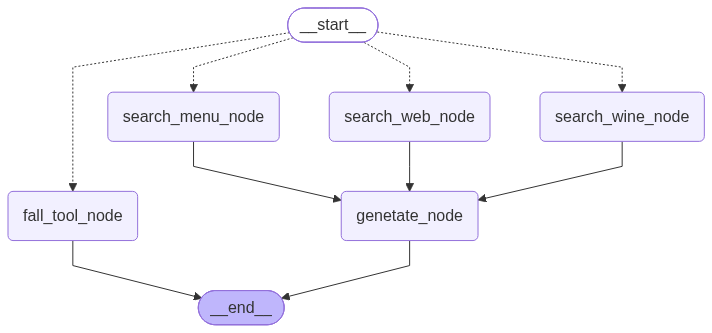

In [38]:
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

## 그래프를 실행한다.

invoke() 메소드로 그래프를 실행하면 최종 결과가 나올 때까지 기다려서 결과를 가져온다.

In [39]:
pprint(graph.invoke({'question': '스테이크 메뉴의 가격은 얼마인가요?'}))

{'answer': '스테이크 메뉴의 가격은 다음과 같습니다:\n'
           '- 시그니처 스테이크: ₩35,000\n'
           '- 안심 스테이크 샐러드: ₩26,000 (출처: 문서)',
 'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'source': './data/restaurant_menu.txt', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
               Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'source': './data/restaurant_menu.txt', 'menu_name': '안심 스테이크 샐러드', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')],
 'question': '스테이크 메뉴의 가격은 얼마인가요?'}


In [40]:
pprint(graph.invoke({'question': '채식주의자를 위한 메뉴가 있나요?'}))

{'answer': '제공된 문서에는 채식주의자를 위한 메뉴에 대한 정보가 포함되어 있지 않습니다.',
 'documents': [Document(id='b2ea8e7a-b3bc-4bcf-b859-aef2f2d94a47', metadata={'menu_number': '5', 'source': './data/restaurant_menu.txt', 'menu_name': '가든 샐러드'}, page_content='5. 가든 샐러드\n    가격: ₩12,000\n    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱\n    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.'),
               Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_number': '6', 'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.')],
 'question': '채식주의자를 위한 메뉴가 있나요?'}


In [41]:
pprint(graph.invoke({'question': '주요 식재료가 야채로만 구성된 메뉴가 있나요?'})['answer'])

("주요 식재료가 야채로만 구성된 메뉴는 '가든 샐러드'입니다. 이 메뉴의 주요 식재료는 유기농 믹스 그린, 체리 토마토, 오이, 당근으로, "
 '모두 야채입니다(출처: 가든 샐러드).')


stream() 메소드로 그래프를 실행하면 노드 하나를 통과할 때 마다 결과를 가져온다.

In [42]:
for output in graph.stream({'question': '스테이크 메뉴의 가격은 얼마인가요?'}):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'상태: {value.keys()}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)
        
print(f'최종 답변:\n{value["answer"]}')

실행한 노드: search_menu_node
상태: dict_keys(['documents'])
노드를 실행한 결과: {'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '1', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '8', 'menu_name': '안심 스테이크 샐러드'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')]}
----------------------------------------------------------------------------------------------------
실행한 노드: genetate_node
상태: dict_keys(['answer'])
노드를 실행한 결과

# 인간 개입 시스템(Human In The Loop, HITL)

AI 시스템의 자동화된 처리와 사람의 전문 지식을 결합하는 방식으로 의사결정 과정에 사람이 개입하여 결과를 검토, 승인, 수정, 보완하는 하이브리드 인공지능 방법론으로 AI의 높은 처리 속도와 자동화 이점에 사람의 직관, 도덕적 판단, 도메인 전문성을 결합하여 시스템의 신뢰성과 정확도를 극대화하는 것을 목적으로 한다.

시스템의 결정이나 출력에 대해 사람이 검토하고 개입할 수 있는 지점을 제공해서 AI의 효율성과 사람의 판단력을 모두 활용한다.

<img src="./HITL.png" width="1200" align="left" />

<img src="./HITL2.png" width="1200" align="left" />

<img src="./HITL3.png" width="1200" align="left" />

# 인간 개입 시스템(Human In The Loop, HITL) 과정 구현하기

LangGraph의 중단점(breakpoint)은 그래프 실행을 특정 단계에서 중지할 때 사용한다.

## 체크포인트 지정

LangGraph가 대화 기록을 기억할 수 있도록 도와주는 내장 메모리 클래스 MemorySaver를 사용하기 위해 import 한다.

MemorySaver는 LangGraph가 제공하는 가장 기본적인 인메모리(In-memory) 체크포인터이고 체크포인터란 게임의 이어하기 기능과 같이 사용자와 AI가 주고받은 메시지나 현재 상태를 기억해두었다가, 다음 대화가 시작될 때 그 기록을 다시 불러오는 역할을 한다.

In [43]:
from langgraph.checkpoint.memory import MemorySaver

대화 기록을 담아둘 비어 있는 메모리 객체를 생성한다.

In [44]:
memory = MemorySaver()

그래프를 컴파일할 때 중단점을 추가한다.

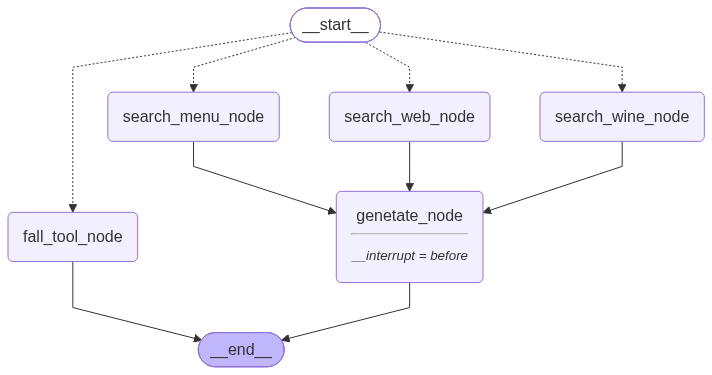

In [45]:
# checkpointer를 지정하면 이전 대화 기억 기능을 그래프에 넣어줘서 중간에 멈춰도 데이터가 날아가지 않게 보존한다.
# interrupt_before는 그래프를 실행하다가 지정된 노드가 실행되기 직전에 그래프 실행을 일적으로 중지한다.
graph = builder.compile(checkpointer=memory, interrupt_before=['genetate_node'])
display(Image(graph.get_graph().draw_mermaid_png()))

## 그래프 일시 중지 확인

그래프를 일시 중지하려면 중단된 지점 부터 이어서 실행할 수 있도록 thread_id를 지정해서 그래프를 실행해야 한다.

In [46]:
thread = {'configurable': {'thread_id': 'breakpoint_test'}}

그래프 일시 중지 사용하려면 stream() 메소드를 사용해서 thread_id를 지정하고 그래프를 실행한다.

In [47]:
input_ = {'question': '스테이크 메뉴의 가격은 얼마인가요?'}

for output in graph.stream(input_, thread):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)

실행한 노드: search_menu_node
노드를 실행한 결과: {'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'source': './data/restaurant_menu.txt', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')]}
----------------------------------------------------------------------------------------------------
실행한 노드: __interrupt__
노드를 실행한 결과: ()
--------------------------------------------------

## 그래프 일시 중지 상태 확인

In [48]:
# 일시 중지된 그래프의 상태를 가져온다.
# get_state() 메소드의 인수로 그래프를 실행할 때 지정한 thread_id를 넘겨서 thread_id에 해당되는 그래프의 일시 중지 상태를 얻어올 수 있다.
current_state = graph.get_state(thread)
print('----- 그래프 일시 중지 상태 -----')
# 그래프 일시 중지 상태를 출력해보면 현재 일시 중지 상태인 그래프가 공유하는 상태값(values)과 다음에 실행할 노드(next) 등의 정보를 확인할 수 있다.
print(current_state)
print('-' * 100)
# genetate_node 실행전에 그래프가 일시 중지되서 answer에는 할당된 값이 없다.
print(current_state.values.get('answer', '없는데 에베벱'))

----- 그래프 일시 중지 상태 -----
StateSnapshot(values={'question': '스테이크 메뉴의 가격은 얼마인가요?', 'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'source': './data/restaurant_menu.txt', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')]}, next=('genetate_node',), config={'configurable': {'thread_id': 'breakpoint_test', 'checkpoint_ns': '', 'checkpoint_id': '1f1d19b8-0480-6335-800

In [49]:
current_state.next

('genetate_node',)

## 일시 중지된 그래프를 중단된 부분부터 실행

일시 중지된 그래프를 이어서 실행하려면 stream() 메소드의 첫 번째 인수(질문이 들어가는 자리)에 `None`을 지정해서 실행해야 한다.  
일시 중지된 그래프에 새 질문을 넣어서 실행하면 AI 기존 기억을 밀어버리고 새 대화를 시작한다.

In [50]:
for output in graph.stream(None, thread):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)

실행한 노드: genetate_node
노드를 실행한 결과: {'answer': '스테이크 메뉴의 가격은 다음과 같습니다:\n- 시그니처 스테이크: ₩35,000\n- 안심 스테이크 샐러드: ₩26,000 (출처: 문서)'}
----------------------------------------------------------------------------------------------------


In [51]:
current_state = graph.get_state(thread)
print(current_state)
print('-' * 100)
# 그래프가 끝까지 실행되서 다음에 실행할 노드가 없다.
print(current_state.next)
print(current_state.values.get('answer', '없는데 에베벱'))

StateSnapshot(values={'question': '스테이크 메뉴의 가격은 얼마인가요?', 'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'source': './data/restaurant_menu.txt', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')], 'answer': '스테이크 메뉴의 가격은 다음과 같습니다:\n- 시그니처 스테이크: ₩35,000\n- 안심 스테이크 샐러드: ₩26,000 (출처: 문서)'}, next=(), config={'configurable': {'thread_id': 'breakpoint_test', 'checkpoint

## 인간이 개입하기

In [52]:
thread = {'configurable': {'thread_id': 'breakpoint_update'}}
input_ = {'question': '매운 음식이 있나요?'}

for output in graph.stream(input_, thread):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)

실행한 노드: search_menu_node
노드를 실행한 결과: {'documents': [Document(id='87b9fa5e-030b-4faf-886e-2929c5d905f9', metadata={'menu_number': '10', 'source': './data/restaurant_menu.txt', 'menu_name': '티라미수'}, page_content='10. 티라미수\n     가격: ₩9,000\n     주요 식재료: 마스카포네 치즈, 에스프레소, 카카오 파우더, 레이디핑거 비스킷\n     설명: 부드러운 마스카포네 치즈 크림과 에스프레소에 적신 레이디핑거 비스킷을 층층이 쌓아 만든 이탈리아 정통 디저트입니다. 고소한 카카오 파우더를 듬뿍 뿌려 풍미를 더했습니다. 커피의 쌉싸름함과 치즈의 부드러움이 조화롭게 어우러집니다.'), Document(id='6afb4d17-042c-4046-8713-28de7ac43f3b', metadata={'menu_name': '치킨 콘피', 'source': './data/restaurant_menu.txt', 'menu_number': '9'}, page_content='9. 치킨 콘피\n    가격: ₩23,000\n    주요 식재료: 닭다리살, 허브, 마늘, 올리브 오일\n    설명: 닭다리살을 허브와 마늘을 넣은 올리브 오일에 저온에서 장시간 조리한 프랑스 요리입니다. 부드럽고 촉촉한 육질이 특징이며, 로즈메리 감자와 제철 채소를 곁들여 제공합니다. 레몬 제스트를 뿌려 상큼한 향을 더했습니다.')]}
----------------------------------------------------------------------------------------------------
실행한 노드: __interrupt__
노드를 실행한 결과: ()
----------------------------------------------------------------------------------

In [53]:
current_state = graph.get_state(thread)
print(current_state.next)
print(current_state.values['question'])
print(current_state.values.get('answer'))

('genetate_node',)
매운 음식이 있나요?
None


일시 중지된 그래프의 상태를 강제로 업데이트 한다.

In [54]:
input_ = {'question': '달달한 요리가 있나요?'}

# update_state() 메소드의 인수로 thread_id와 업데이트 할 내용을 넘겨서 일시 중지된 그래프의 상태를 강제로 업데이트 할 수 있다.
graph.update_state(thread, input_)

{'configurable': {'thread_id': 'breakpoint_update',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d19b8-5c18-6082-8002-d255083e1582'}}

In [55]:
current_state = graph.get_state(thread)
print(current_state.next)
print(current_state.values['question'])
print(current_state.values.get('answer'))

('genetate_node',)
달달한 요리가 있나요?
None


In [56]:
for output in graph.stream(None, thread):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)

실행한 노드: genetate_node
노드를 실행한 결과: {'answer': '제공된 문서에는 달달한 요리에 대한 정보가 포함되어 있지 않습니다.'}
----------------------------------------------------------------------------------------------------


In [57]:
current_state = graph.get_state(thread)
print(current_state.values.get('answer'))

제공된 문서에는 달달한 요리에 대한 정보가 포함되어 있지 않습니다.


# Self RAG

기존 RAG의 한계점(무조건적인 검색 수행, 환각 현상, 외부 문서의 무분별한 수용 문제 등)을 해결하기 위해 고안된 자기 반영(self reflective) 능력을 추가한 RAG 이다.

LLM이 생성 과정에서 특수한 토큰(reflection tokens)을 사용하여 스스로 검색의 필요성을 판단하고, 검색된 문서의 관련성을 평가하며, 생성된 답변의 신뢰성을 검증해서 정보 검색, 생성, 평가를 통합하고 더 정확하고 관련성 높은 응답을 생성하는 것을 목표로 한다.

<img src="./selfRAG.png" width="1200" align="left" />

<img src="./selfRAG2.png" width="1200" align="left" />

<img src="./selfRAG3.png" width="800" align="left" />

## 주요 단계

① 검색 여부 결정(판단): 질문에 대한 외부 지식 필요 여부를 판단한다.  
&nbsp;&nbsp;&nbsp;▶ 질문과 질문에 의해서 생성된 답변을 입력받아 어떤 검색기를 사용하여 몇 개의 청크를 검색할지 결정해서 추가 정보가 필요한지 판단한다.  
&nbsp;&nbsp;&nbsp;▶ yes: 외부 지식이 반드시 필요함  
&nbsp;&nbsp;&nbsp;▶ no: 모델의 내부 직식만으로 충분함  
&nbsp;&nbsp;&nbsp;▶ continue: 문맥을 더 이어가며 추가 정보가 필요한지 판단

② 검색된 문서 관련성 평가: 검색된 문서(청크)가 질문과 관련이 있는지 여부를 판단한다.  
&nbsp;&nbsp;&nbsp;▶ 질문과 검색된 청크를 입력받아 각 청크가 질문에 유용한 정보를 제공하는지 평가해서 관련 없는 정보를 필터링하여 품질을 향상한다.  
&nbsp;&nbsp;&nbsp;▶ relevant(관련 있는): 검색된 청크가 질문에 유용함(채택)  
&nbsp;&nbsp;&nbsp;▶ irrelevant(관련 없는): 검색된 청크가 관련 없는 노이즈 문서(배제)  

③ 생성된 답변의 환각(근거, 신뢰성) 평가: 생성된 답변이 검색된 문서의 내용에 기반하는지 여부를 판단한다.  
&nbsp;&nbsp;&nbsp;▶ 질문과 검색된 청크, 생성된 답변을 입력받아 청크의 정보에 근거가 있는지 평가해서 환각을 감지하고 정보의 신뢰성을 확인한다.  
&nbsp;&nbsp;&nbsp;▶ fully supported: 생성된 내용이 문서에 완전히 근거함(환각 없음)  
&nbsp;&nbsp;&nbsp;▶ partially supported: 생성된 내용이 문서에 부분적으로 근거함  
&nbsp;&nbsp;&nbsp;▶ no supported: 생성된 내용이 문서에 없는 내용을 지어냄(환각 발생)

④ 생성된 답변의 유용성 평가: 최종 답변이 사용자 질문을 얼마나 잘 해결했는지 5점 척도로 점수화 한다.  
&nbsp;&nbsp;&nbsp;▶ 질문과 최종 답변을 입력받아 생성된 답변이 질문에 유용한 응답인지 평가해서 응답의 품질과 관련성을 수치화 한다.

# Self RAG 구현하기

## 검색 결과 평가기

검색된 문서가 사용자의 질문과 실제로 관련이 있는지 LLM을 통해 검증하고 필터링한다.

검색 결과 평가기가 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [58]:
class GradeDocuments(BaseModel):
    # docstring
    # 구조화된 출력을 위해서 LLM에게 전달하여 LLM이 클래스의 목적을 이해하는 데 도움을 준다.
    '''질문과 검색기가 가져온 문서들의 관련성 여부를 판별한다.'''
    # 문자열(str) 타입의 binary_score라는 필드를 선언한다.
    # description을 이용해서 이 필드에는 yes/no 형태의 값이 들어가야 한다고 LLM에게 지시한다. 실제는 결과는 프롬프트의 지침에 따라 들어간다.
    binary_score: str = Field(description='질문과 검색기가 가져온 문서들이 관련이 있습니까? "yes" 또는 "no"로 답하세요.')

In [59]:
print(json.dumps(GradeDocuments.model_json_schema(), indent=2, ensure_ascii=False))

{
  "description": "질문과 검색기가 가져온 문서들의 관련성 여부를 판별한다.",
  "properties": {
    "binary_score": {
      "description": "질문과 검색기가 가져온 문서들이 관련이 있습니까? \"yes\" 또는 \"no\"로 답하세요.",
      "title": "Binary Score",
      "type": "string"
    }
  },
  "required": [
    "binary_score"
  ],
  "title": "GradeDocuments",
  "type": "object"
}


LLM 모델 및 구조화된 출력 모델을 만든다. 

In [60]:
# 모델의 무작위성(창의성)을 완전히 배제하고, 항상 일관되고 엄격한 판찬(결정론적 답변)을 내리도록 모델을 선언한다.
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
# LLM이 최종적으로 응답할 데이터 구조에 맞춰 답변을 반환하도록 모델을 선언한다.
llm_grade_documents = llm.with_structured_output(GradeDocuments)

프롬프트를 만든다.

In [61]:
system_grade_documents = dedent('''
    당신은 사용자 질문에 대한 검색 결과의 관련성을 아래의 평가 기준을 바탕으로 평가하는 전문가입니다.
    
    [평가 기준]: 
        - 문서가 질문의 주요 단어나 유사어를 포함하는지 평가하세요.
        - 문서의 전반적인 주제가 질문의 의도와 일치하는지 평가하세요.
        - 질문의 일부를 다루거나 맥락 정보를 제공하는 문서도 고려해서 평가하세요.
        - 직접적인 답이 아니더라도 답변 형성에 도움될 정보 포함 여부도 평가하세요.
        
    [채점 방식]: 
        - 관련이 있으면 'yes', 관련이 없으면 'no'로 평가하세요.
        - 불확실할 경우 기본값은 'no'로 설정하세요.
        
    [평가시 핵심 고려 사항]: 
        - 단어 매칭에만 의존하지 말고, 질의의 전체 맥락을 고려하세요.
        - 완전한 답변이 아니더라도 유용한 정보가 포함되어 있다면 관련 있음으로 평가하세요.
        
    당신의 평가는 정보 검색 시스템의 성능을 향상시키는데 매우 중요합니다. 균형 잡힌 평가 결과를 제공해 주세요.
''')

prompt_grade_documents = ChatPromptTemplate.from_messages([
    ('system', system_grade_documents),
    ('human', '[검색된 문서]:\n{document}\n\n[사용자 질문]:\n{question}')
])

RAG chain을 만든다.

In [62]:
rag_chain_grade_documents = prompt_grade_documents | llm_grade_documents

검색 결과 평가기 테스트 하기 위해서 질문에 의해 검색된 문서를 얻어온다.

In [63]:
question = '대표 메뉴는 무엇인가요?'
# question = '스테이크 메뉴의 가격은 얼마인가요?'
docs = menu_db.similarity_search(query=question, k=4)
docs

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt', 'menu_number': '1'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
 Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_number': '6', 'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.'),
 Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부

검색 결과 평가기를 실행해서 관련이 있다고 판정된 문서만 뽑아낸다.

In [64]:
relevant_docs = []
for doc in docs:
    print(doc.page_content)
    print('-' * 100)
    # 위에서 구성한 RAG chain에 검색된 문서와 사용자 질문을 전달해서 LLM이 판단한 결과를 바탕으로 관련된 문서를 뽑는다.
    relevance = rag_chain_grade_documents.invoke({'document': doc.page_content, 'question': question})
    print(f'문서 관련성: {relevance}')
    print('-' * 100)
    # 문서 관련성 평가가 'yes'인 문서만 relevant_docs에 추가한다.
    if relevance.binary_score == 'yes':
        relevant_docs.append(doc)

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.
----------------------------------------------------------------------------------------------------
문서 관련성: binary_score='yes'
----------------------------------------------------------------------------------------------------
6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
----------------------------------------------------------------------------------------------------
문서 관련성: binary_score='yes'
----------------------------------------------------------------------------------------------------
8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다

In [65]:
relevant_docs

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt', 'menu_number': '1'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
 Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_number': '6', 'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.'),
 Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부

## 답변 생성기

질문과 컨텍스트(context, 참고 문서)를 인수로 받아서 주어진 컨텍스트만 참고해서 답변하는 함수를 만든다.

In [66]:
def generator_rag_answer(question: str, docs: List[Document]) -> str:
    # 프롬프트를 만든다.
    system = dedent('''
        다음 지시사항에 따라서 어떠한 외부 정보나 지식도 사용하지 말고 오직 주어진 문맥(context)에 기반하여 질문에 답변하세요.

        [지시 사항]: 
            - 질문과 관련된 정보를 문맥에서 신중하게 확인하세요.
            - 답변에 질문과 직접 관련된 정보만 사용하세요.
            - 문맥에 명시되지 않은 내용에 대해 추축하지 마세요.
            - 불필요한 정보를 피하고, 답변을 간결하고 명확하게 작성하세요.
            - 문맥에서 답을 찾을 수 없으면 '주어진 정보만으로는 답할 수 없습니다.'라고 답변하세요.
    ''')

    prompt = ChatPromptTemplate.from_messages([
        ('system', system),
        ('human', '[컨텍스트(context)]:\n{context}\n\n[사용자 질문]:\n{question}\n\n[답변]:')
    ])
    # LLM 모델을 만든다.
    llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
    
    # 프롬프트로 넘겨줄 컨텍스트를 Document 객체의 본문(page_content)만 꺼내서 하나의 문자열로 연결하는 함수
    def format_docs(docs):
        return '\n\n'.join([doc.page_content for doc in docs])
    
    # RAG chain을 만들고 실행한다.
    rag_chain = prompt | llm | StrOutputParser()
    generation = rag_chain.invoke({'context': format_docs(docs), 'question': question})
    # 최종 답변을 리턴시킨다.
    return generation

사용자 질문과 사용자 질문에 따라 벡터저장소에서 검색해온 문서 중에서 검색 결과 평가기를 통과한 문서들을 인수로 넘겨서 답변을 생성한다.

In [67]:
generation = generator_rag_answer(question, relevant_docs)
print(generation)

주어진 정보만으로는 답할 수 없습니다.


## 환각 평가기

답변 생성기로 생성한 답변이 주어진 사실에 근거해서 답변했는가 평가한다.

환각 평가기가 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [68]:
class GradeHallucinations(BaseModel):
    '''답변 생성기로 생성한 답변의 환각(주어진 사실에 근거해서 답변했는가) 여부를 판별한다.'''
    binary_score: str = Field(description='답변이 사실에 기반하고 있는가? "yes" 또는 "no"로 답하세요.')

In [69]:
print(json.dumps(GradeHallucinations.model_json_schema(), indent=2, ensure_ascii=False))

{
  "description": "답변 생성기로 생성한 답변의 환각(주어진 사실에 근거해서 답변했는가) 여부를 판별한다.",
  "properties": {
    "binary_score": {
      "description": "답변이 사실에 기반하고 있는가? \"yes\" 또는 \"no\"로 답하세요.",
      "title": "Binary Score",
      "type": "string"
    }
  },
  "required": [
    "binary_score"
  ],
  "title": "GradeHallucinations",
  "type": "object"
}


LLM 모델 및 구조화된 출력 모델을 만든다.

In [70]:
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
llm_grade_hallucinations = llm.with_structured_output(GradeHallucinations)

프롬프트를 만든다.

In [71]:
system_grade_hallucinations = dedent('''
    당신은 LLM이 생성한 답변이 주어진 사실에 근거해서 답변했는가 평가하는 전문가입니다.
    LLM이 생성한 답변을 검토하고 해당 답변이 주어진 사실에 완전히 뒷받침하는지 판단합니다.
    
    [평가 기준]: 
        - 답변에 주어진 사실이나 명확히 추론할 수 있는 정보 이외의 내용이 없어야 합니다.
        - 답변의 모든 핵심 내용이 주어진 사실에 비롯되어야 합니다.
        - 사실적 정확성에 집중하고, 글쓰기 스타일이나 완전정은 평가하지 않습니다.
        
    [채점 방식]: 
        - 'yes': 답변이 사실에 기반하고 있으며, 주어진 사실에 의해 완전히 뒷받침됩니다.
        - 'no': 답변이 사실에 근거하지 않은 정보나 주장이 포함되어 있습니다.
        
    당신의 평가는 AI가 생성한 답변의 신뢰성과 사실적 정확성을 보장하는데 매우 중요합니다. 철저하고 비판적인 시각으로 평가에 임해 주세요.
''')

prompt_grade_hallucinations = ChatPromptTemplate.from_messages([
    ('system', system_grade_hallucinations),
    ('human', '[주어진 사실]:\n{documents}\n\n[LLM 답변]:\n{generation}')
])

RAG chain을 만든다.

In [72]:
rag_chain_grade_hallucinations = prompt_grade_hallucinations | llm_grade_hallucinations

환각 평가기를 실행한다.

In [73]:
hallucination = rag_chain_grade_hallucinations.invoke({'documents': relevant_docs, 'generation': generation})
print(f'환각 평가: {hallucination}')

환각 평가: binary_score='no'


## 답변 평가기

LLM이 생성한 답변이 사용자의 질문에 적합한지 평가한다.

답변 평가기가 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [74]:
class GradeAnswer(BaseModel):
    '''LLM의 답변이 질문에 부합하는지 여부를 판별한다.'''
    binary_score: str = Field(description='답변이 질문에 부합하는가? "yes" 또는 "no"로 답하세요.')

In [75]:
print(json.dumps(GradeAnswer.model_json_schema(), indent=2, ensure_ascii=False))

{
  "description": "LLM의 답변이 질문에 부합하는지 여부를 판별한다.",
  "properties": {
    "binary_score": {
      "description": "답변이 질문에 부합하는가? \"yes\" 또는 \"no\"로 답하세요.",
      "title": "Binary Score",
      "type": "string"
    }
  },
  "required": [
    "binary_score"
  ],
  "title": "GradeAnswer",
  "type": "object"
}


LLM 모델 및 구조화된 출력 모델을 만든다.

In [76]:
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
llm_grade_answer = llm.with_structured_output(GradeAnswer)

프롬프트를 만든다.

In [77]:
system_grade_answer = dedent('''
    당신은 LLM이 생성한 답변이 사용자 질문을 효과적으로 다루고 해결하는지 평가하는 전문가입니다.
    사용자의 질문을 주의 깊게 분석하여 핵심 의도와 요구사항을 파악해서 LLM이 생성한 답변이 질문을 충분히 해결하는지 판단합니다.
    
    [평가 기준]: 
        - LLM이 생성한 답변이 사용자 질문과 직접적으로 관련되어야 합니다.
        - 사용자 질문의 모든 측면이 다뤄져야 합니다.
        - 제공된 정보가 정확하고 최신이어야 합니다.
        - 답변이 명확하고 이해하기 쉬워야 합니다.
        - 사용자 질문의 요구 사항에 맞는 상세한 답변이어야 합니다.
        
    [채점 방식]: 
        - 'yes': LLM이 생성한 답변이 질문을 효과적으로 해결합니다.
        - 'no': LLM이 생성한 답변이 질문을 효과적으로 해결하지 못하거나, 핵심적인 요소가 누락되어 있습니다.
        
    당신의 평가는 AI가 생성한 답변의 품질과 효과성을 보장하는데 매우 중요한 역학을 합니다. 균형잡힌 신중한 평가를 내릴 수 있도록 노력해 주세요.
''')

prompt_grade_answer = ChatPromptTemplate.from_messages([
    ('system', system_grade_answer),
    ('human', '[사용자 질문]:\n{question}\n\n[LLM 답변]:\n{generation}')
])

RAG chain을 만든다.

In [78]:
rag_chain_grade_answer = prompt_grade_answer | llm_grade_answer

답변 평가기를 실행한다.

In [79]:
print(f'질문: {question}')
print(f'답변: {generation}')

answer_score = rag_chain_grade_answer.invoke({'question': question, 'generation': generation})
print(f'답변 평가: {answer_score}')

질문: 대표 메뉴는 무엇인가요?
답변: 주어진 정보만으로는 답할 수 없습니다.
답변 평가: binary_score='no'


## 질문 재작성기

답변 평가기 실행 결과 답변이 만족스럽지 않으면 질문을 재작성 한다.

기존 질문을 인수로 벡터저장소 검색에 최적화된 질문으로 재작성 하는 함수를 만든다.

In [80]:
def rewrite_question(question: str) -> str:
    '''주어진 사용자 질문을 벡터저장소 검색에 최적화된 형태로 재작성 합니다.'''
    # 프롬프트를 만든다.
    system = dedent('''
        당신은 입력된 사용자 질문을 벡터저장소 검색에 최적화된 형태로 변환하는 질문 재작성 전문가입니다.
        입력된 사용자 질문을 주의 깊에 분석하여 그 안에 담긴 근본적인 의미와 의도를 파악하는데 집중하세요.
        당신의 목표는 아래의 지침을 따라 더 효과적이고 관련성 높은 문서를 검색할 수 있도록 질문을 새로 만드는 것입니다.
        
        [지침]:
            - 사용자 질문에서 핵심 개념과 주요 대상을 식별하고 강조합니다.
            - 약어나 모호한 용어는 풀어서 사용합니다.
            - 관련 문서에 등장할 수 있는 동의어나 연관된 용어를 포함합니다.
            - 사용자 질문의 원래 의도와 범위는 유지합니다.
            - 복잡한 질문은 간단하고 집중된 하위 질문으로 나눕니다.
            
        목표는 검색의 효과를 높이는 것이지, 질문의 본질적인 의미를 바꾸는 것이 아닙니다.
    ''')

    prompt = ChatPromptTemplate.from_messages([
        ('system', system),
        ('human', '[[사용자 질문]:\n{question}\n\n[개선된 질문]:')
    ])
    # LLM 모델을 만든다.
    llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
    # RAG chain을 만들고 실행한다.
    rag_chain = prompt | llm | StrOutputParser()
    re_generation = rag_chain.invoke({'question': question})
    # 최종 답변을 리턴시킨다.
    return re_generation

사용자 질문과 인수로 넘겨서 개선된 질문을 생성한다.

In [81]:
re_generation = rewrite_question(question)
print(f'사용자 질문: {question}')
print(f'개선된 질문: {re_generation}')

사용자 질문: 대표 메뉴는 무엇인가요?
개선된 질문: 대표 메뉴의 종류와 특징은 무엇인가요?


질문 재작성기로 생성된 질문으로 벡터저장소에서 검색한다.

In [82]:
docs = menu_db.similarity_search(query=re_generation, k=4)
docs

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'source': './data/restaurant_menu.txt', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
 Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타', 'menu_number': '6'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.'),
 Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'menu_number': '8', 'source': './data/restaurant_menu.txt'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부

# Self RAG LangGraph 구현

## 그래프 상태를 만든다.

LangGraph로 AI의 작업 흐름(검색 -> 채점 -> 재작성 -> 답변 생성)을 제어할 때, 각 노드를이 데이터를 공유하고 업데이트할 수 있는 상태를 만든다.

In [83]:
class SelfRagState(TypedDict):
    question: str # 사용자 질문
    generation: str # LLM 답변
    documents: List[Document] # 사용자 질문으로 벡터저장소에서 검색한 문서, 컨텍스트
    num_generation: int # 무한 루프를 방지하기 위해서 LLM 답변 생성 횟수와 질문을 다시 만드는 횟수

In [84]:
SelfRagState.__annotations__.keys()

dict_keys(['question', 'generation', 'documents', 'num_generation'])

## 노드를 만든다.

LangGraph 워크프로우 각 단계(노드)에 매핑되는 실제 실행되는 함수들을 데이터를 공유하고 업데이트할 수 있는 상태 SelfRagState를 인수로 넘겨서 만든다.

문서를 검색하는 노드

In [85]:
# 상태에서 사용자 질문을 얻어와서 문서를 찾아오는 함수
def retriever_node(state: SelfRagState):
    '''문서를 검색하는 함수'''
    print('----- 문서 검색 -----')
    # 상태에서 사용자 질문을 얻어온다.
    question = state['question']
    # 얻어온 질문으로 벡터저장소에서 가장 유사한 문서들를 얻어온다.
    documents = menu_db.similarity_search(query=question, k=4)
    # 얻어온 문서로 상태를 업데이트한다.
    return {'documents': documents}

답변을 생성하는 노드

In [86]:
# 상태에서 사용자 질문과 벡터저장소에서 검색한 문서를 얻어와서 답변을 생성하는 노드
def generate_node(state: SelfRagState):
    '''답변을 생성하는 함수'''
    print('----- 답변 생성 -----')
    # 답변을 생성하는 generator_rag_answer 함수를 호출할 때 질문과 참고할 문서가 필요하므로 상태에서 사용자 질문과 벡터저장소에서 검색한 문서를 얻어온다.
    question = state['question']
    documents = state['documents']
    # 답변을 생성하는 함수를 실행한다.
    generation = generator_rag_answer(question=question, docs=documents)
    # 상태에서 답변 생성 횟수를 얻어온다. 만약 첫 실행일 경우 값이 없으므로 get() 메소드의 2번째 인수로 기본값을 지정한다.
    num_generation = state.get('num_generation', 0)
    # 답변을 생성할 때 마다 답변 생성 횟수를 1씩 증가시킨다.
    num_generation += 1
    # 생성한 답변과 답변 생성 횟수를 업데이트한다.
    return {'generation': generation, 'num_generation': num_generation}

문서 관련성을 평가하는 노드

In [87]:
# 상태에서 사용자 질문과 벡터저장소에서 검색한 문서를 얻어와서 검색 결과 평가기를 실행해서 관련이 있다고 판정된 문서만 뽑아내는 함수
def grade_documents_node(state: SelfRagState):
    '''검색된 문서의 관련성을 평가하는 함수'''
    print('----- 문서 관련성 평가 -----')
    # 문서 관련성 평가를 위해서 사용자 질문과 벡터저장소에서 검색한 문서를 얻어온다.
    question = state['question']
    documents = state['documents']
    
    # 벡터저장소에서 검색한 각각의 문서를 평가한다.
    # 문서 관련성 평가를 통과한 합격 문서들만 따로 모아두기 위한 빈 리스트를 선언한다.
    filter_docs = []
    for doc in documents:
        # 검색 결과 평가기에 벡터저장소에서 검색한 각각의 개별 문서와 질문을 넘겨서 검색 결과를 평가한다.
        score = rag_chain_grade_documents.invoke({'document': doc.page_content, 'question': question})
        # 검색 결과 평가가 'yes'인 문서만 filter_docs 리스트에 추가한다.
        if score.binary_score == 'yes':
            print('----- 문서 관련성 있음 -----')
            filter_docs.append(doc)
        else:
            print('----- 문서 관련성 없음 -----')
    
    # 문서 평가 결과 관련성 있는 문서를 업데이트한다.
    return {'documents': filter_docs}

질문을 개선하는 노드

In [88]:
# 검색된 문서들이 사용자 질문과 관련이 없어서 상태에서 사용자 질문을 얻어와서 검색 효율을 높이기 위해 질문을 다시 만드는 함수
def transform_node(state: SelfRagState):
    '''질문을 개선하는 함수'''
    print('----- 질문 개선 -----')
    # 질문을 재작성하는 rewrite_question 함수를 호출할 때 질문만 필요하므로 상태에서 사용자 질문을 얻어온다.
    question = state['question']
    # 질문을 재작성하는 함수를 실행한다.
    re_question = rewrite_question(question)
    # 상태에서 질문 재작성 횟수를 얻어온다. 만약 첫 실행일 경우 값이 없으므로 get() 메소드의 2번째 인수로 기본값을 지정한다.
    num_generation = state.get('num_generation', 0)
    # 질문을 재작성 할 때 마다 질문 재작성 횟수를 1씩 증가시킨다.
    num_generation += 1
    # 재작성한 질문과 질문 재작성 횟수를 업데이트한다.
    return {'question': re_question, 'num_generation': num_generation}

## 조건부 엣지를 만든다.

답변을 생성하는 노드로 갈 것인가, 아니면 질문을 다시 만들 것인가 결정하는 조건부 엣지 함수를 만든다.

In [89]:
def generate_self(state: SelfRagState):
    '''답변 생성 여부를 결정하는 조건부 엣지 함수'''
    # 현재까지 답변을 생성한 횟수를 상태에서 얻어온다.
    num_generation = state.get('num_generation', 0)
    
    # 무한 루프를 방지하기 위해서 답변을 생성한 횟수가 지정한 횟수를 초과한다면 답변을 생성하는 노드로 보낸다.
    if num_generation > 2:
        print('----- 답변 생성 횟수 초과 => 답변을 생성하는 노드(generate_node)로 분기 -----')
        return 'generate_node'
    
    # 답변을 생성한 횟수가 지정한 횟수를 초과하지 않았다면 다시 답변을 생성하기위해 컨텍스트 문서를 상태에서 얻어온다.
    documents = state.get('documents', None)
    
    # 얻어온 컨텍스트 문서가 비어있나([] 또는 None) 확인한다.
    if not documents:
        # 컨텍스트가 비어있으면 '사용자 질문과 관련된 문서가 하나도 없다.'는 뜻이므로 질문을 재작성한다.
        print('----- 사용자 질문과 관련된 문서가 하나도 없음 => 질문을 재작성하는 노드(transform_node)로 분기 -----')
        return 'transform_node'
    else:
        # 컨텍스트가 비어있지않으면 '사용자 질문과 관련된 문서가 있다.'는 뜻이므로 답변을 생성한다.
        print('----- 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----')
        return 'generate_node'

LLM이 생성한 답변을 환각 검증과 질문 관련성 검증으로 나눠서 채점하고 분기하는 조건부 엣지 함수를 만든다.

In [90]:
def grade_self(state: SelfRagState):
    '''LLM이 생성한 답변의 품질을 평가하는 조건부 엣지 함수'''
    # 현재까지 질문 재작성 횟수를 상태에서 얻어온다.
    num_generation = state.get('num_generation', 0)
    
    # 무한 루프를 방지하기 위해서 질문 재작성 횟수가 지정한 횟수를 초과한다면 그래프를 종료한다.
    if num_generation > 2:
        print('----- 답변 생성 횟수 초과 => 그래프를 종료하기 위해 END로 분기 -----')
        return 'end'
    
    # 답변 검증(환각 여부와 답변 평가)을 하기 위해서 상태에서 사용자 질문, 참조한 문서 리스트, LLM이 생성한 답변을 얻어온다.
    question, documents, generation = state['question'], state['documents'], state['generation']
    # 환각 평가기의 RAG chain을 실행해서 LLM이 생성한 답변에 대한 환각 평가를 한다.
    hallucination_score = rag_chain_grade_hallucinations.invoke({'documents': relevant_docs, 'generation': generation})
    
    # 환각 여부를 확인한다.
    print('----- 환각 여부 확인 -----')
    if hallucination_score.binary_score == 'yes':
        
        # 환각 현상이 발생되지 않았으므로 답변 평가를 하기 위해서 답변 평가기의 RAG chain을 실행해서 답변 평가를 한다.
        print('----- 환각 현상이 발생되지 않아서 답변을 평가한다. -----')
        # 답변 평가기의 RAG chain을 실행해서 사용자 질문과 LLM의 답변을 평가한다.
        answer_score = rag_chain_grade_answer.invoke({'question': question, 'generation': generation})
        
        # LLM의 답변이 사용자 질문의 의도에 부합 여부를 확인한다.
        if answer_score.binary_score == 'yes':
            # LLM의 답변이 유용한 경우이므로 그래프를 종료한다.
            print('----- LLM의 답변이 사용자 질문의 의도에 부합함 => 그래프를 종료하기 위해 END로 분기 -----')
            return 'useful'
        else:
            # 환각 현상은 발생하지 않았으나 LLM의 답변이 유용하지 않는 경우이므로 '사용자 질문과 전혀 상관없는 답변을 했다.'는 뜻이므로 질문을 재작성한다.
            print('----- LLM의 답변이 사용자 질문의 의도에 부합하지 않음 => 질문을 재작성하는 노드(transform_node)로 분기 -----')
            return 'not useful'
        
    else:
        # 환각 현상이 발생되면 답변을 다시 생성한다.
        print('----- 환각 현상이 발생되서 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----')
        return 'not supported'

## 그래프를 만든다.

상태(SelfRagState)를 공유하는 그래프 객체를 만든다.

In [91]:
builder_main = StateGraph(SelfRagState)

노드를 추가한다.

In [92]:
builder_main.add_node('retriever_node', retriever_node) # 문서 검색 노드
builder_main.add_node('generate_node', generate_node) # 답변 생성 노드
builder_main.add_node('grade_documents_node', grade_documents_node) # 문서 평가 노드
builder_main.add_node('transform_node', transform_node) # 질문 개선 노드

엣지를 추가한다.

In [93]:
# 그래프가 시작되면 사용자 질문으로 벡터저장소에서 관련 문서를 얻어오는 노드로 연결하는 정적 엣지
builder_main.add_edge(START, 'retriever_node')
# 벡터저장소에서 얻어온 문서가 사용자 질문과 관련있나 문서를 평가하는 노드로 연결하는 정적 엣지
builder_main.add_edge('retriever_node', 'grade_documents_node')

# 첫 번째 조건부 엣지 - 문서 평가 후 라우팅(답변 생성 노드, 질문 개선 노드)
builder_main.add_conditional_edges(
    # 조건부 엣지 함수를 실행할 노드
    'grade_documents_node',
    # 실행할 조건부 엣지 함수
    generate_self,
    # 조건부 엣지 함수의 리턴 값에 따른 실행할 노드를 딕셔너리 형태로 지정한다.
    {
        'transform_node': 'transform_node',
        'generate_node': 'generate_node'
    }
)

# 질문을 재작성했으면 재작성한 질문으로 벡터저장소에서 관련 문서를 얻어오는 노드로 연결하는 정적 엣지
builder_main.add_edge('transform_node', 'retriever_node')

# 두 번째 조건부 엣지 - 답변 생성 후 검증(환각 현상, 답변)
builder_main.add_conditional_edges(
    'generate_node',
    grade_self,
    {
        'end': END,
        'useful': END,
        'not useful': 'transform_node',
        'not supported': 'generate_node'
    }
)

그래프를 컴파일한다.

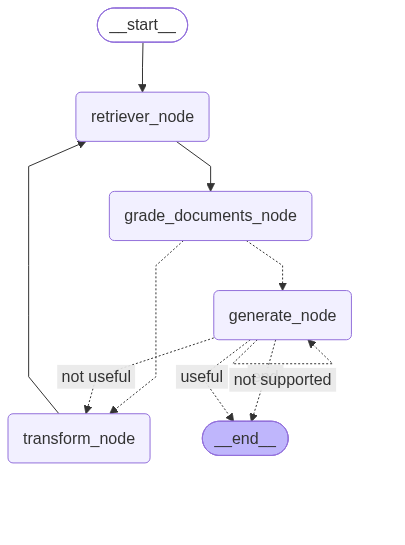

In [94]:
graph_main = builder_main.compile()
display(Image(graph_main.get_graph().draw_mermaid_png()))

그래프를 실행한다.

invoke() 메소드는 전체 그래프가 실행된 후 최종 결과를 가져온다.

In [95]:
# input_ = {'question': '대표 메뉴는 무엇인가요?'}
# input_ = {'question': '스테이크 메뉴의 가격은 얼마인가요?'}
# input_ = {'question': '채식주의자를 위한 메뉴를 추천해주세요.'}
input_ = {'question': '이 식당의 대표 메뉴는 무엇인가요? 주재료는 무엇인가요?'}
final_answer = graph_main.invoke(input_)

----- 문서 검색 -----
----- 문서 관련성 평가 -----
----- 문서 관련성 있음 -----
----- 문서 관련성 있음 -----
----- 문서 관련성 있음 -----
----- 문서 관련성 있음 -----
----- 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----
----- 답변 생성 -----
----- 환각 여부 확인 -----
----- 환각 현상이 발생되지 않아서 답변을 평가한다. -----
----- LLM의 답변이 사용자 질문의 의도에 부합함 => 그래프를 종료하기 위해 END로 분기 -----


In [96]:
print(final_answer['generation'])

이 식당의 대표 메뉴는 시그니처 스테이크입니다. 주재료는 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스입니다.


stream() 메소드는 그래프가 실행되는 과정을 실시간(노드 단위)으로 추적하고 모니터링 할 수 있다.

In [97]:
input_ = {'question': '이 식당의 대표 메뉴는 무엇인가요? 주재료는 무엇인가요?'}
for output in graph_main.stream(input_):
    # print(output)
    for key, value in output.items():
        print(f'실행하는 노드: {key}')
        print(f'{key} 실행 후 상태값: {value}')
        print('\n' + '-' * 100 + '\n')

----- 문서 검색 -----
실행하는 노드: retriever_node
retriever_node 실행 후 상태값: {'documents': [Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt', 'menu_number': '1'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'menu_number': '8', 'source': './data/restaurant_menu.txt'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.'), Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_number': '6', 'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타'}, page_content

In [98]:
print(value['generation'])

이 식당의 대표 메뉴는 시그니처 스테이크입니다. 주재료는 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스입니다.


# 서브 그래프

LangGraph에서 서브 그래프는 복잡한 에이전트의 워크프로우를 `모듈화`하고 관리하기 위해, `독립된 하나의 그래프`를 다른 그래프(부모 그래프) 내부의 `특정 노드`로 포함시키는 기능이다.

거대한 단일 그래프를 만들다 보면 노드와 엣지가 지나치게 많아져 유지보수가 어려워지는데, 서브 그래프를 활용하면 논리적 단위로 쪼개어 관리할 수 있다.
<br>
<img src="./subgraphs.png" width="1200" align="left" />

<img src="./subgraphs2.png" width="1200" align="left" />

## 서브 그래프의 장점

① 검색, 검증, 코드 실행 등 로직을 독립된 그래프로 격리하여 개발할 수 있다.  
② 서브 그래프는 부모 그래프와 동일한 상태를 공유할 수도 있고, 독자적인 상태를 가질 수도 있다.  
③ 잘 정의된 서브 그래프를 여러 부모 그래프에 재사용할 수 있다.  
④ 전체 워크플로우를 블랙박스 형태의 모듈로 나누어 볼 수 있어 흐름 파악과 테스트가 수월해진다.

# 서브 그래프를 만든다.

파이썬 연산자 중에서 더하기 기능을 수행하는 add를 LangGraph의 `리듀서`로 사용하기 위해 import 한다.  
LangGraph에서 `리듀서`를 만들기 위해 Annotated를 import 한다.  

In [99]:
from operator import add
from typing import Annotated

## 서브 그래프 상태를 만든다.

In [100]:
class SearchState(TypedDict):
    question: str # 사용자 질문
    documents: Annotated[List[Document], add] # 도구로 검색한 Document 객체, add 리듀서를 적용한다.
    filtered_documents: List[Document] # 도구로 검색한 Document 객체 중에서 실제로 사용자 질문과 관련있는 Document 객체

In [101]:
SearchState.__annotations__.keys()

dict_keys(['question', 'documents', 'filtered_documents'])

## 서브 그래프에서 사용할 노드를 만든다.

메뉴를 검색하는 노드

In [102]:
def menu_search_node(state: SearchState):
    '''레스토랑 메뉴 리스트에서 메뉴 정보를 검색하는 노드'''
    print('----- 레스토랑 메뉴 검색 도구 실행 -----')
    question = state['question']
    # 레스토랑 메뉴 검색 도구(search_menu)를 실행해서 메뉴 정보를 얻어온다.
    documents = search_menu.invoke(question)
    return {'documents': documents}

와인을 검색하는 노드

In [103]:
def wine_search_node(state: SearchState):
    '''레스토랑 와인 리스트에서 와인 정보를 검색하는 노드'''
    print('----- 레스토랑 와인 검색 도구 실행 -----')
    question = state['question']
    # 레스토랑 와인 검색 도구(search_wine)를 실행해서 메뉴 정보를 얻어온다.
    documents = search_wine.invoke(question)
    return {'documents': documents}

웹을 검색하는 노드

In [104]:
def web_search_node(state: SearchState):
    '''레스토랑 메뉴 또는 레드토랑 와인 리스트에 없는 정보나 최신 정보는 웹에서 검색하는 노드'''
    print('----- 웹 검색 도구 실행 -----')
    question = state['question']
    # Tavily web 검색 도구(search_web)를 실행해서 메뉴 정보를 얻어온다.
    documents = search_web.invoke(question)
    return {'documents': documents}

메뉴, 와인, 웹 검색 도구에서 검색한 문서 필터링하는 노드

In [105]:
def filter_documents_node(state: SearchState):
    '''메뉴, 와인, 웹 검색 도구에서 검색된 문서와 사용자 질문의 관련성을 평가하고 필터링하는 노드'''
    print('----- 검색된 문서들과 사용자 질문의 관련성 평가 -----')
    question, documents = state['question'], state['documents']
    # 검색된 문서들과 사용자 질문의 관련성을 평가한다.
    filtered_documents = []
    for doc in documents:
        score = rag_chain_grade_documents.invoke({'document': doc, 'question': question})
        if score.binary_score == 'yes':
            print('----- 검색된 문서들과 사용자 질문이 관련성 있음 -----')
            filtered_documents.append(doc)
        else:
            print('----- 검색된 문서들과 사용자 질문이 관련성 없음 -----')
    return {'filtered_documents': filtered_documents}

## 서브 그래프를 만든다.

상태(SearchState)를 공유하는 서브 그래프 객체를 만든다.

In [106]:
builder_sub = StateGraph(SearchState)

노드를 추가한다.

In [107]:
builder_sub.add_node('menu_search_node', menu_search_node)
builder_sub.add_node('wine_search_node', wine_search_node)
builder_sub.add_node('web_search_node', web_search_node)
builder_sub.add_node('filter_documents_node', filter_documents_node)

엣지를 추가한다.

In [108]:
builder_sub.add_edge(START, 'menu_search_node')
builder_sub.add_edge(START, 'wine_search_node')
builder_sub.add_edge(START, 'web_search_node')

builder_sub.add_edge('menu_search_node', 'filter_documents_node')
builder_sub.add_edge('wine_search_node', 'filter_documents_node')
builder_sub.add_edge('web_search_node', 'filter_documents_node')

builder_sub.add_edge('filter_documents_node', END)

서브 그래프를 컴파일한다.

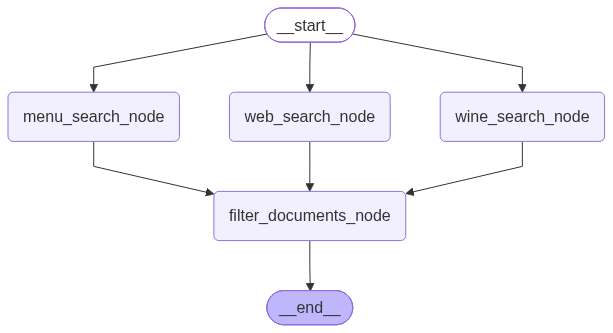

In [109]:
graph_sub = builder_sub.compile()
display(Image(graph_sub.get_graph().draw_mermaid_png()))

## 병렬 노드(Parallel Nodes)

LangGraph에서 병렬 노드 실행은 여러 작업을 동시에 처리하여 응답 속소를 높이거나, 서로 다른 관점(멀티 에이전트, 다중 문서 검색 등)의 결과를 종합할 때 사용되는 기능으로 Fan-out(분기)과 Fan-in(합류) 구조를 통해 병렬 처리를 지원한다.

Fan-out: 한 노드에서 출발한 엣지가 여러 노드로 향하면, LangGraph는 해당 노드들을 병렬로 실행한다.  
Fan-in: 병렬로 실행된 노드들이 모두 끝난 후, 다음 단계의 단일 노드가 실행된다.

<img src="./subgraphs3.png" width="800" align="left" />

서브 그래프를 실행한다.

In [110]:
input_ = {'question': '스테이크 메뉴가 있으면 추천해주세요. 그리고 어울리는 와인도 소개해주세요.'}
final_answer = graph_sub.invoke(input_)

----- 레스토랑 메뉴 검색 도구 실행 -----
----- 레스토랑 와인 검색 도구 실행 -----
----- 웹 검색 도구 실행 -----


C:\Users\enjoy\AppData\Local\Temp\ipykernel_7652\543606674.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tavily_search = TavilySearchResults(max_results=2)


----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----


In [111]:
final_answer['filtered_documents']

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
 Document(metadata={'source': 'https://powermax.tistory.com/49'}, page_content='Jan 23, 2024 · 또한, 캘리포니아의 카베르네 소비뇽 (Cabernet Sauvignon)과 아르헨티나의 말벡 (Malbec)도 립아이 스테이크와 잘 어울리는 와인입니다. 등심 스테이크 등심 스테이크는 등뼈에 가까운 부위의 고기로, 육즙이 적당하고 쫄깃한 특징이 있습니다. Mar 19, 2025 · 오늘은 스테이크의 맛을 한층 더 업그레이드해줄 사이드 메뉴와 함께 어울리는 와인까지 추천해 드릴게요! 에서도 근사한 레스토랑 분위기를 느낄 수 있도록 풍성하게 준비했답니다🥗 🥔 1. 감자 요리 (매쉬드 포테이토, 웨지 감자) Mar 23, 2025 · 바르바레스코 (Barbaresco)와 바롤로 (Barolo) 같은 네비올로 (Nebbiolo) 품종의 와인도 스테이크와 잘 어울리는 와인으로 꼽힌다. 아르헨티나의 말벡 (Malbec)은 육즙이 풍부한 스테이크와 궁합이 좋으며, 탄닌이 적절하고 과실미가 뛰어나 부담 없이 즐길 수 있다.'),
 Document(metadata={'source': 'https://m.blog.naver.c

## 조건부 엣지로 병렬 노드 실행

LangGraph에서 조건부 엣지와 병렬 노드를 결합하면, 상태나 조건에 따라 어떤 노드들을 동시에 실행할지 동적으로 제어할 수 있다.

하나의 도구를 선택할 때 사용하는 단일 데이터 모델을 정의한다.

In [112]:
class ToolSelector(BaseModel):
    '''사용자의 질문을 가장 적절한 도구로 라우팅합니다.'''
    # tool이라는 필드를 만들고 이 필드는 'search_menu', 'search_wine', 'search_web'이라는 3가지 문자열 중 하나만 들어올 수 있도록 제한한다.
    tool: Literal['search_menu', 'search_wine', 'search_web'] = Field(
        description='사용자의 질문에 따라 다음 도구 중 하나를 선택하십시오: search_menu, search_wine, search_web'
    )

복수 개의 도구 선택(병렬 선택)을 처리하기 위해 ToolSelector들을 리스트 형태로 감싸는 모델을 정의한다.

In [113]:
class ToolSelectors(BaseModel):
    '''사용자의 질문에 부합하는 적절한 도구들을 선택하십시오.'''
    # 위에서 정의한 단일 도구 선택 모델(ToolSelector)을 리스트 형태로 여러 개 담을 수 있게 한다.
    # 이렇게 만들어 주면 복합 질문이 들어왔을 때 여러 도구를 동시에 골라낼 수 있다.
    tools: List[ToolSelector] = Field(
        description='사용자의 질문에 따라 다음 도구 중 하나 또는 그 이상을 선택하십시오.: search_menu, search_wine, search_web'
    )

구조화된 출력을 지원하는 LLM을 설정한다.

In [114]:
llm_tool_selector = llm.with_structured_output(ToolSelectors)

프롬프트를 만든다.

In [115]:
system_tool_selector = dedent('''
    당신은 사용자의 질문을 적절한 도구(tool)로 라우팅(연결)하는 전문 AI 어시스턴트입니다.
    
    다음의 지침에 따르세요:
        - 레스토랑의 메뉴에 대한 질문은 'search_menu' 도구를 사용하세요.
        - 와인 추천이나 페이링(음식 궁합) 정보에 대한 질문은 'search_wine' 도구를 사용하세요.
        - 그 외의 정보나 최신 데이터가 필요한 질문은 'search_web' 도구를 사용하세요.
        
    항상 사용자의 질문에 기반하여 가장 적절한 도구를 선택해야 합니다.
''')

prompt_tool_selector = ChatPromptTemplate.from_messages([
    ('system', system_grade_documents),
    ('human', '{question}')
])

RAG chain을 만든다.

In [116]:
rag_chain_tool_selector = prompt_tool_selector | llm_tool_selector

In [117]:
print(rag_chain_tool_selector.invoke({'question': '채식주의자를 위한 메뉴가 있나요?'}))
print(rag_chain_tool_selector.invoke({'question': '스테이크 메뉴의 가격과 어울리는 와인을 추천해주세요.'}))
print(rag_chain_tool_selector.invoke({'question': '스테이크 메뉴가 있으면 추천해주세요. 그리고 스테이크의 유래에 대해서 알려주세요.'}))
rag_chain_tool_selector.invoke({'question': '스테이크 메뉴와 스테이크에 어울리는 와인을 추천해주세요. 그리고 스테이크의 유래에 대해서 알려주세요.'})

tools=[ToolSelector(tool='search_menu')]
tools=[ToolSelector(tool='search_wine')]
tools=[ToolSelector(tool='search_menu'), ToolSelector(tool='search_web')]


ToolSelectors(tools=[ToolSelector(tool='search_menu'), ToolSelector(tool='search_wine'), ToolSelector(tool='search_web')])

## 서브 그래프 상태를 만든다.
<br>

```
class ToolSearchState(TypedDict):
    question: str # 사용자 질문
    documents: Annotated[List[Document], add] # 도구로 검색한 Document 객체, add 리듀서를 적용한다.
    filtered_documents: List[Document] # 도구로 검색한 Document 객체 중에서 실제로 사용자 질문과 관련있는 Document 객체
    datasources: List[str] # 사용자 질문에 따라 실행할 도구들의 목록
```

question, documents, filtered_documents는 SearchState 클래스에 정의된 상태이므로 SearchState 클래스를 상속받아 ToolSearchState를 만든다.

In [118]:
class ToolSearchState(SearchState):
    # question: str
    # documents: Annotated[List[Document], add]
    # filtered_documents: List[Document]
    datasources: List[str] # 사용자 질문에 따라 실행할 도구들의 목록

In [119]:
ToolSearchState.__annotations__.keys()

dict_keys(['question', 'documents', 'filtered_documents', 'datasources'])

## 서브 그래프에서 사용할 노드를 만든다.

질문을 분석해서 실행할 도구를 선택는 노드를 만든다.

In [120]:
def question_analyze_node(state: ToolSearchState):
    '''사용자 질문을 분석해서 search_menu, search_wine, search_web 도구 중에서 사용할 도구를 결정하는 노드'''
    print('----- 사용자 질문 분석 -----')
    # 상태에서 사용자 질문을 얻어온다.
    question = state['question']
    # 얻어온 사용자 질문에 따라서 실행할 도구 목록을 얻어온다.
    results = rag_chain_tool_selector.invoke({'question': question})
    # 얻어온 도구 목록에서 도구 이름만 얻어와서 리스트로 만든다.
    datasources = [result.tool for result in results.tools]
    # 도구 목록이 저장된 리스트를 업데이트한다.
    return {'datasources': datasources}

## 선택된 노드에 따라 도구를 실행할 노드를 결정하는 조건부 엣지 함수를 만든다.

In [121]:
def question_analyze(state: ToolSearchState) -> List[str]:
    '''사용자 질문을 분석해서 search_menu, search_wine, search_web 도구 중에서 사용할 도구를 결정하는 조건부 엣지 함수'''
    # 상태에서 샤용하려는 도구 목록을 얻어온다.
    datasources = state['datasources']
    
    # 사용할 도구가 메뉴 검색 하나뿐이라면 menu_search_node로 가라고 그래프에게 지시하기 위해 'menu'를 리턴한다.
    if set(datasources) == {'search_menu'}:
        return ['menu_search_node']
    # 사용할 도구가 와인 검색 하나뿐이라면 wine_search_node로 가라고 그래프에게 지시하기 위해 'wine'을 리턴한다.
    elif set(datasources) == {'search_wine'}:
        return ['wine_search_node']
    # 사용할 도구가 웹 검색 하나뿐이라면 websearch_node로 가라고 그래프에게 지시하기 위해 'web'을 리턴한다.
    elif set(datasources) == {'search_web'}:
        return ['websearch_node']
    # 사용할 도구가 메뉴, 와인 검색이라면 menu_search_node, wine_search_node로 가라고 그래프에게 지시하기 위해 'menu_wine'을 리턴한다.
    elif set(datasources) == {'search_menu', 'search_wine'}:
        return ['menu_search_node', 'wine_search_node']
    # 사용할 도구가 메뉴, 웹 검색이라면 menu_search_node, web_search_node로 가라고 그래프에게 지시하기 위해 'menu_web'을 리턴한다.
    elif set(datasources) == {'search_menu', 'search_web'}:
        return ['menu_search_node', 'web_search_node']
    # 사용할 도구가 와인, 웹 검색이라면 wine_search_node, web_search_node로 가라고 그래프에게 지시하기 위해 'wine_web'을 리턴한다.
    elif set(datasources) == {'search_wine', 'search_web'}:
        return ['wine_search_node', 'web_search_node']
    # 위의 모든 조건을 만족하지 않는다면 3개의 도구 실행하는 노드로 가라고 그래프에게 지시하기 위해 'all'을 리턴한다.
    else:
        return ['menu_search_node', 'wine_search_node', 'web_search_node']

## 서브 그래프를 만든다.

상태(ToolSearchState)를 공유하는 서브 그래프 객체를 만든다.

In [122]:
builder_sub = StateGraph(ToolSearchState)

노드를 추가한다.

In [123]:
builder_sub.add_node('question_analyze_node', question_analyze_node)
builder_sub.add_node('menu_search_node', menu_search_node)
builder_sub.add_node('wine_search_node', wine_search_node)
builder_sub.add_node('web_search_node', web_search_node)
builder_sub.add_node('filter_documents_node', filter_documents_node)

엣지를 추가한다.

In [124]:
builder_sub.add_edge(START, 'question_analyze_node')

# 조건부 엣지
builder_sub.add_conditional_edges(
    'question_analyze_node',
    question_analyze,
    # question_analyze 함수의 실행 결과에 따라 리스트에 명시된 노드 중 해당되는 곳으로 분기한다. 병렬처리
    ['menu_search_node', 'wine_search_node', 'web_search_node']
)

builder_sub.add_edge('menu_search_node', 'filter_documents_node')
builder_sub.add_edge('wine_search_node', 'filter_documents_node')
builder_sub.add_edge('web_search_node', 'filter_documents_node')

builder_sub.add_edge('filter_documents_node', END)

서브 그래프를 컴파일한다.

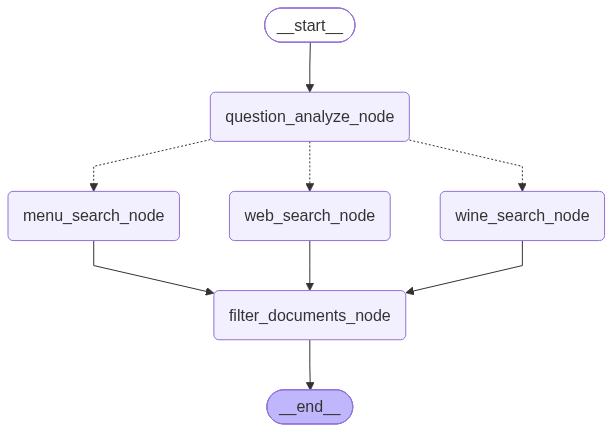

In [125]:
graph_sub = builder_sub.compile()
display(Image(graph_sub.get_graph().draw_mermaid_png()))

In [126]:
input_ = {'question': '스테이크 메뉴가 있으면 추천해주세요.'}
final_answer = graph_sub.invoke(input_)

----- 사용자 질문 분석 -----
----- 레스토랑 메뉴 검색 도구 실행 -----
----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----


In [127]:
final_answer['filtered_documents']

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_name': '시그니처 스테이크', 'menu_number': '1', 'source': './data/restaurant_menu.txt'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.')]

In [128]:
input_ = {'question': '스테이크 메뉴가 있으면 추천해주세요. 그리고 어울리는 와인도 소개해주세요.'}
final_answer = graph_sub.invoke(input_)

----- 사용자 질문 분석 -----
----- 레스토랑 메뉴 검색 도구 실행 -----
----- 레스토랑 와인 검색 도구 실행 -----
----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----


In [129]:
final_answer['filtered_documents']

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.')]

In [130]:
input_ = {'question': '파스타 메뉴가 있으면 추천해주세요. 그리고 파스타의 유래에 대해 알려주세요.'}
final_answer = graph_sub.invoke(input_)

----- 사용자 질문 분석 -----
----- 레스토랑 메뉴 검색 도구 실행 -----
----- 웹 검색 도구 실행 -----
----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----


In [131]:
final_answer['filtered_documents']

[Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_number': '6', 'menu_name': '해산물 파스타', 'source': './data/restaurant_menu.txt'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.'),
 Document(metadata={'source': 'https://m.blog.naver.com/rokmcssj/20185188044'}, page_content='본문 바로가기\n\n# 블로그\n\n## 카테고리 이동 그리움 양모펠트 공방\n\n검색\n\n지중해 건강요리\n\n### 파스타의 역사와 대중화\n\n프로필 \n\n2013. 4. 7. 3:54\n\n이웃추가\n\n파스타의 역사\n\n스파게티? 파스타??\n\n보통 이탈리안 파스타를 그냥 스파게티라고 부르는데 스파게티는 수 천가지 다양한 파스타의\n\n한 종류일 뿐이다. 파스타란 밀가루를 이용해서 만든 국수 형태의 음식을 통틀어 일컫는\n\n말인데, 경우에 따라서는 메밀가루나 보리가루등 다른 곡식분을 이용하기도 한다.\n\n스파게티 같은 국수 모양뿐 아니라 라비올리, 또르텔리니처럼 속을 채운 만두 모양이나 둥글게\n\n빚어내는 요끼 같은 것도 모두 파스타에 속한다.\n\n파스타 위에 얹어내는 소스도 파스타의 종류만큼이나 다양해서 우리가 흔히 먹는 토마토\n\n소스나 크림 소스 외에 상상할 수 없는 독특한 소스들이 많다.\n\n파스타의 유래\n\n전설은 많고 정설은 없다. 기원전 3천년경에 이미 국수 형태의 음식을 만들어 먹었다고 하는 중국에는\n\n밀가루로 만든 국

# 서브 그래프를 메인 그래프에 통합하기

```
class SelfRagState(TypedDict):
    question: str # 사용자 질문
    generation: str # LLM 답변
    documents: List[Document] # 사용자 질문으로 벡터저장소에서 검색한 문서, 컨텍스트
    num_generation: int # 무한 루프를 방지하기 위해서 LLM 답변 생성 횟수와 질문을 다시 만드는 횟수
```

우리가 위에서 만들었던 Self RAG 그래프의 모든 노드가 공유하며 읽고 쓰는 상태를 만든다.

In [132]:
class SelfRagOverallState(SelfRagState):
    # question: str # 사용자 질문
    # generation: str # LLM 답변
    # documents: List[Document] # 사용자 질문으로 벡터저장소에서 검색한 문서, 컨텍스트
    # num_generation: int # 무한 루프를 방지하기 위해서 LLM 답변 생성 횟수와 질문을 다시 만드는 횟수
    filtered_documents: List[Document] # 도구로 검색한 Document 객체 중에서 실제로 사용자 질문과 관련있는 Document 객체

In [133]:
SelfRagOverallState.__annotations__.keys()

dict_keys(['question', 'generation', 'documents', 'num_generation', 'filtered_documents'])

## 통합 그래프를 만든다.

Self RAG 그래프에 서브 그래프를 통합하기 위해서 상태(SelfRagOverallState)를 공유하는 통합 그래프 객체를 만든다.

In [134]:
builder_main = StateGraph(SelfRagOverallState)

## 통합 그래프에 통합할 서브 그래프를 컴파일한다.

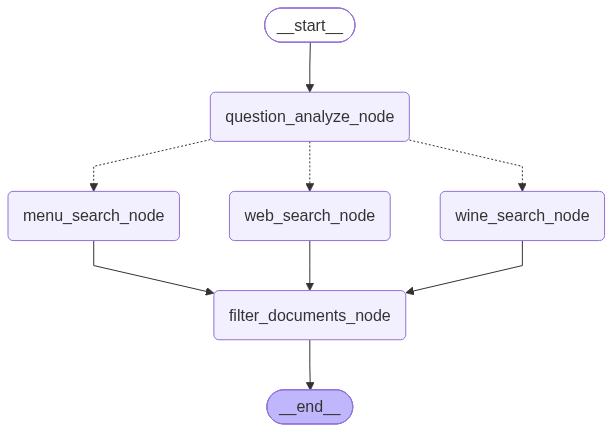

In [135]:
graph_sub = builder_sub.compile()
display(Image(graph_sub.get_graph().draw_mermaid_png()))

## 노드를 만든다.

In [136]:
builder_main.add_node('graph_sub', graph_sub) # 통합 그래프에 통합할 서브 그래프를 노드로 정의한다.
builder_main.add_node('generate_node', generate_node) # 답변 생성 노드
builder_main.add_node('transform_node', transform_node) # 질문 개선 노드

## 엣지를 만든다.

In [137]:
builder_main.add_edge(START, 'graph_sub') # START에서 서브 그래프로 연결되는 정적 엣지를 만든다.

# 첫 번째 조건부 엣지 - 서브 그래프에서 분기하는 조건부 엣지를 추가한다.
builder_main.add_conditional_edges(
    'graph_sub',
    generate_self,
    {
        'transform_node': 'transform_node',
        'generate_node': 'generate_node'
    }
)

# 질문을 재작성했으면 재작성한 질문으로 벡터저장소에서 관련 문서를 얻어오는 노드로 연결하는 정적 엣지
builder_main.add_edge('transform_node', 'graph_sub')

# 두 번째 조건부 엣지 - 답변 생성 후 검증(환각 현상, 답변)
builder_main.add_conditional_edges(
    'generate_node',
    grade_self,
    {
        'end': END,
        'useful': END,
        'not useful': 'transform_node',
        'not supported': 'generate_node'
    }
)

## 통합 그래프를 컴파일한다.

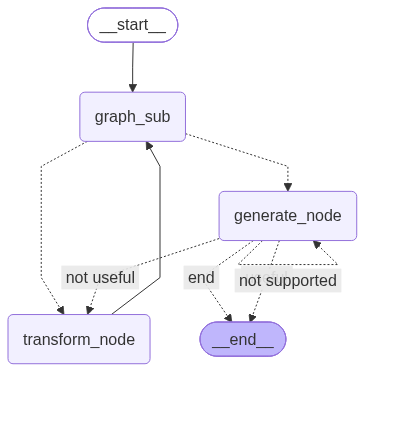

In [138]:
graph_main = builder_main.compile()
display(Image(graph_main.get_graph().draw_mermaid_png()))

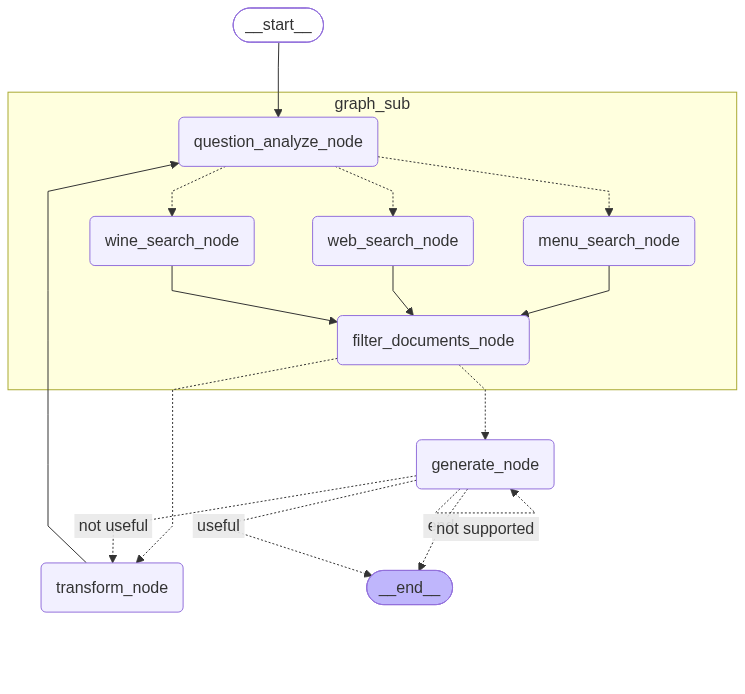

In [139]:
# get_graph() 메소드의 xray 속성의 속성 값을 True로 지정하면 통합 그래프에 통합되는 서브 그래프의 구조도 확인할 수 있다.
display(Image(graph_main.get_graph(xray=True).draw_mermaid_png()))

In [140]:
input_ = {'question': '이 식당의 대표 메뉴는 무엇인가요? 주재료는 무엇인가요?'}
final_answer = graph_main.invoke(input_)

----- 사용자 질문 분석 -----
----- 레스토랑 메뉴 검색 도구 실행 -----
----- 웹 검색 도구 실행 -----
----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----
----- 답변 생성 -----
----- 환각 여부 확인 -----
----- 환각 현상이 발생되지 않아서 답변을 평가한다. -----
----- LLM의 답변이 사용자 질문의 의도에 부합함 => 그래프를 종료하기 위해 END로 분기 -----


In [141]:
final_answer['generation']

'이 식당의 대표 메뉴는 시그니처 스테이크입니다. 주재료는 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스입니다.'

In [142]:
input_ = {'question': '스테이크 메뉴가 있나요? 어울리는 와인이 있을까요?'}
final_answer = graph_main.invoke(input_)

----- 사용자 질문 분석 -----
----- 레스토랑 메뉴 검색 도구 실행 -----
----- 레스토랑 와인 검색 도구 실행 -----
----- 검색된 문서들과 사용자 질문의 관련성 평가 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 있음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 검색된 문서들과 사용자 질문이 관련성 없음 -----
----- 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----
----- 답변 생성 -----
----- 환각 여부 확인 -----
----- 환각 현상이 발생되서 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----
----- 답변 생성 -----
----- 환각 여부 확인 -----
----- 환각 현상이 발생되서 답변을 생성한다. => 답변을 생성하는 노드(generate_node)로 분기 -----
----- 답변 생성 -----
----- 답변 생성 횟수 초과 => 그래프를 종료하기 위해 END로 분기 -----


In [143]:
final_answer['generation']

'네, 스테이크 메뉴로는 시그니처 스테이크와 안심 스테이크 샐러드가 있습니다. 시그니처 스테이크와 잘 어울리는 와인으로는 바롤로 몬프리바토 2017이 있습니다.'

# 자가 교정형(Corrective) RAG

CRAG는 일반적인 RAG 시스템의 가장 큰 약점 중 하나인 `검색된 문서가 유용하지 않거나 잘못되었을 때(환각) 발생하는 오류`를 해결하기 위해 제안된 방식이다.  
기존 RAG는 검색기가 가져온 문서가 질문과 상관이 없더라고 그대로 LLM에게 넘겨주기 때문에 잘못된 답변을 생성할 위험이 크다. CRAG는 이를 방지하기 위해 검색된 문서의 품질을 `스스로 교정하는 단계를 추가`했다.

CRAG는 기존 RAG 시스템을 개선하여 검색된 정보의 품질과 관련성을 향상시키는 접근 방식으로 문서 관련성 평가, 지식 정제, 필요시 외부 지식 탐색, 그리고 정제된 지식을 바탕으로 한 답변을 생성한다.

<img src="./CRAG.png" width="1200" align="left" />

<img src="./CRAG2.png" width="1200" align="left" />

<img src="./CRAG3.png" width="800" align="left" />

## 지식 정제기

검색된 문서에서 질문과 관련된 핵심 지식을 추출하고 관련성을 평가한다.

지식 정제기가 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [159]:
class RefinedKnowledge(BaseModel):
    '''문서에서 추출한 정제된 지식을 나타냅니다.'''
    knowledge: str = Field(description='문서에서 추출해낸 핵심 지식 정보')
    binary_score: Literal['yes', 'no'] = Field(description='문서가 질문과 관련이 있는지 여부를 "yes" 또는 "No"로 나타낸다.')

LLM 모델 및 구조화된 출력 모델을 만든다.

In [160]:
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
llm_grade_refined = llm.with_structured_output(RefinedKnowledge)

프롬프트를 만든다.

In [161]:
system_refined = dedent('''
    당신은 지식 정제(Knowledge Refinement) 전문가 입니다.
    당신의 임무는 아래의 지시사항에 따라서 주어진 문서에서 제공된 질문과 관련된 핵심 정보를 추출하고, 그 관련성을 평가하는 것입니다.
    
    [지시사항]:
        - 질문과 문서를 주의 깊게 읽습니다.
        - 질문에 답하는데 관련된 문서 내의 주요 정보를 식별합니다.
        - 각 주요 정보에 대해 간결하게 추출하고 요약합니다.
        - 질문에 대한 관련성을 'yes'(관련 있음) 또는 'no'(관련 없음)로 평가합니다.
        
    [출력 예시]:
        - AI 시스템은 학습 데이터에 존재하는 편향을 나타낼 수 있습니다.(yes)
        - 의사 결정에 AI을 사용하는 것은 프라이버시 문제를 제기합니다.(yes)
        - 기계 학습 모델은 상당한 컴퓨팅 자원을 필요로 합니다.(no)
        
    사실적이고 객관적인 정보를 추출하는데 집중하시고 개인적인 의견이나 추축은 피해야 합니다.
    기본적으로 3~5개의 핵심 정보를 제공하는 것을 목표로 하되, 문서에 관련 내용이 풍부한 경우에는 그 이상을 포함해도 좋습니다.
''')

prompt_refined = ChatPromptTemplate.from_messages([
    ('system', system_refined),
    ('human', '[검색된 문서]\n{document}\n\n[사용자 질문]\n{question}')
])

RAG chain을 만든다.

In [162]:
rag_chain_refined = prompt_refined | llm_grade_refined

RAG chain을 실행한다.

In [163]:
question = '이 식당의 대표 메뉴는 무엇인가요? 주재료는 무엇인가요?'
docs = search_menu.invoke(question)

In [164]:
docs

[Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt', 'menu_number': '1'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
 Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '8', 'menu_name': '안심 스테이크 샐러드'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.')]

In [165]:
for doc in docs:
    print('----- 검색된 문서 -----')
    print(doc.page_content)
    result = rag_chain_refined.invoke({'document': doc, 'question': question})
    print(f'정제된 지식: {result.knowledge}')
    print(f'정제된 지식 평가: {result.binary_score}')
    print('-' * 100)

----- 검색된 문서 -----
1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.
정제된 지식: 대표 메뉴는 시그니처 스테이크이며, 주재료는 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스입니다.
정제된 지식 평가: yes
----------------------------------------------------------------------------------------------------
----- 검색된 문서 -----
8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
정제된 지식: 대표 메뉴는 안심 스테이크 샐러드이며, 주재료는 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈입니다.
정제된 지식 평가: yes
----------------------------------------------------------------------------------------------------


## 검색 결과 평가기

검색된 문서가 사용자의 질문과 얼마나 관련있는지 3가지 등급 적절함(correct), 부적절함(incorrect), 애매함(ambiguous)으로 평가하는 문서 관련성 평가기이다.

검색 결과 평가기가 최종적으로 응답할 데이터 구조를 BaseModel 클래스를 상속받아 정의한다.

In [166]:
class MultiGradeDocuments(BaseModel):
    '''사용자 질문에 따라 검색된 문서의 관련성 평가를 3가지 기준으로 한다.'''
    multi_score: Literal['correct', 'incorrect', 'ambiguous'] = Field(
        description='문서의 질문 관련성을 적절함(correct), 부적절함(incorrect), 애매함(ambiguous) 중 하나로 판별하세요.'
    )

LLM 모델 및 구조화된 출력 모델을 만든다.

In [167]:
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0)
llm_multi_grade = llm.with_structured_output(MultiGradeDocuments)

프롬프트를 만든다.

In [168]:
system_multi_grade = dedent('''
    당신은 검색된 문서가 사용자의 질문과 얼마나 관련이 있는지 평가하는 전문가입니다.
    당신의 역할은 정보 검색 시스템의 품질을 향상시키는 데 매우 중요합니다.
    
    [평가 기준]
        - 문서가 질문의 주요 단어나 유사어를 포함하는지 키워드 관련성을 평가한다.
        - 문서의 전반적인 주제가 질문의 의도와 일치하는지 의미적 관련성을 평가한다.
        - 질문의 일부를 다루거나 맥락 정보를 제공하는 문서도 고려해서 평가한다.
        - 직접적인 답이 아니더라도 답변 형성에 도움될 정보를 포함하는가 하는 답변 가능성을 평가한다.
        
    [점수 체계]
        - 적절함(correct): 문서가 명확하게 관련이 있고, 질문에 답하는 데 필요한 정보를 포함하는 경우.
        - 부적절함(incorrect): 문서가 명확하게 관련이 없거나, 질문에 도움이 되지 않는 정보를 포함하는 경우.
        - 애매함(ambiguous): 문서의 관련성이 불분명하거나, 일부 관련 정보는 있지만 유용성이 확실하지 않거나, 혹은 질문과 약간만 관련이 있는 경우.
        
    단순한 단어 매칭이 아닌 질문의 전체 맥락을 고려하고 완벽한 답변이 아니더라도 유용한 정보가 있다면 관련있다고 판단하세요.
    당신의 평가는 정보 검색 시스템의 전반적인 성능을 향상시키는 데 결정적인 역할을 합니다.
    한쪽에 치우침 없이 객관적이며 신중한 평가를 내리도록 노력해 주세요.
''')

prompt_multi_grade = ChatPromptTemplate.from_messages([
    ('system', system_multi_grade),
    ('human', '[검색된 문서]\n{document}\n\n[사용자 질문]\n{question}')
])

RAG chain을 만든다.

In [169]:
rag_chain_multi_grade = prompt_multi_grade | llm_multi_grade

RAG chain을 실행한다.

In [170]:
question = '채식주의자 메뉴가 있나요?'
docs = search_menu.invoke(question)

In [171]:
docs

[Document(id='b2ea8e7a-b3bc-4bcf-b859-aef2f2d94a47', metadata={'menu_number': '5', 'source': './data/restaurant_menu.txt', 'menu_name': '가든 샐러드'}, page_content='5. 가든 샐러드\n    가격: ₩12,000\n    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱\n    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.'),
 Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'menu_name': '해산물 파스타', 'source': './data/restaurant_menu.txt', 'menu_number': '6'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스\n    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.')]

In [172]:
for doc in docs:
    print('----- 검색된 문서 -----')
    print(doc.page_content)
    result = rag_chain_multi_grade.invoke({'document': doc, 'question': question})
    print(f'문서 관련성 평가: {result.multi_score}')
    print('-' * 100)

----- 검색된 문서 -----
5. 가든 샐러드
    가격: ₩12,000
    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.
문서 관련성 평가: correct
----------------------------------------------------------------------------------------------------
----- 검색된 문서 -----
6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
문서 관련성 평가: incorrect
----------------------------------------------------------------------------------------------------


# Corrective RAG 그래프 구현

그래프의 모든 노드가 공유하며 읽고 쓰는 상태를 MessagesState 클래스를 상속받아 만든다.  
MessagesState 클래스를 상속받으면 별도로 작성하지 않아도 대화 기록을 저장하는 `messages: Annotated[List[AnyMessage], add_messages]` 필드가 기본적으로 생성된다.

In [220]:
class CorrectiveRagState(MessagesState):
    # messages: Annotated[List[AnyMessage], add_messages] # 대화 히스토리
    question: str # 사용자 질문
    generation: str # LLM의 답변
    # 사용자 질문에 따라서 검색된 문서들과 그 문서들의 채점 결과를 저장하는 리스트 - 1차 검색
    documents: List[Tuple[Document, str]] # 검색된 문서 리스트(문서, 점수)
    # 1차 검색 문서가 부적절하거나 애매할 경우, 위부 웹 검색 등을 통해 부족한 지식을 추가로 찾아오거나 정제해서 교정 및 보강된 문서들의 채점 결과를 누적해서
    # 저장하는 리스트 - 2차 검색
    knowledge: List[Tuple[Document, str]] # 지식을 보강한 결과 리스트(문서, 점수)
    num_generation: int # 무한 루프를 방지하기 위한 답변 생성 횟수

In [221]:
CorrectiveRagState.__annotations__.keys()

dict_keys(['messages', 'question', 'generation', 'documents', 'knowledge', 'num_generation'])

## 노드를 만든다.

문서를 검색하는 노드

In [222]:
def menu_retriever_node(state: CorrectiveRagState):
    '''레스토랑 메뉴를 검색하는 노드'''
    print('----- 문서 검색 -----')
    question = state['question']
    docs = search_menu.invoke(question)
    # 검색된 문서들로 documents를 업데이트 해야하므로 (검색된 문서, 점수) 형태로 맞춘 리스트를 만든다.
    # 단순히 search_menu 도구에서 문서를 검색해와서 문서 관련성 평가를 실시하지 않았으므로 점수는 'ambiguous'으로 초기화한다.
    documents = [(doc, 'ambiguous') for doc in docs]
    # 1차 검색 결과로 상태를 업데이트 한다.
    return {'documents': documents}

문서 관련성 평가 노드

In [223]:
def grade_documents_node(state: CorrectiveRagState):
    '''사용자 질문과 검색된 문서의 관련성을 평가하는 노드'''
    print('----- 문서 관련성 평가 -----')
    # 문서 관련성 평가를 위해 상태에서 사용자 질문, 1차 검색 문서 리스트, 지식 보강 누적 리스트를 얻어온다.
    question = state['question']
    documents = state.get('documents', []) # 1차 검색 문서 리스트
    knowledge = state.get('knowledge', []) # 지식 보강 누적 리스트
    
    # 채점이 완료된 (검색된 문서, 점수)를 모아둘 빈 리스트를 선언한다.
    scored_docs = []
    # 1차 검색 문서 리스트의 문서들을 반복하며 3가지 기준으로 평가한다.
    for doc, _ in documents:
        # 3가지 기준으로 평가하는 검색 결과 평가기 RAG chain을 실행해서 사용자 질문과 1차 검색 문서의 관련성을 평가한다.
        score = rag_chain_multi_grade.invoke({'question': question, 'document': doc.page_content})
        # 문서의 관련성을 평가 결과를 모두 소문자로 변환한다.
        score = score.multi_score.lower()
        # 문서 관련성 평가 점수가 correct라면 채점이 완료된 검색된 문서를 모아놓을 리스트와 지식 보강 누적 리스트에 추가한다.
        # incorrect 또는 ambiguous일 겅우에는 채점이 완료된 검색된 문서를 모아놓을 리스트에만 추가한다.
        if score == 'correct':
            print('----- 문서 관련성 있음 -----')
            scored_docs.append((doc, 'correct'))
            knowledge.append((doc, 'correct'))
        elif score == 'incorrect':
            print('----- 문서 관련성 없음 -----')
            scored_docs.append((doc, 'incorrect'))
        else:
            print('----- 문서 관련성 모호함 -----')
            scored_docs.append((doc, 'ambiguous'))
        # 채점이 완료된 검색된 문서와 지식 보강 누적 리스트로 상태를 업데이트 한다.
        return {'documents': documents, 'knowledge': knowledge}

지식 정제 노드

In [224]:
def knowledge_node(state: CorrectiveRagState):
    '''지식을 정제하는 노드'''
    print('----- 지식 정제 -----')
    # 지식 정제를 하기 위해서 사용자 질문과 문서 관련성 평가를 통과(correct)한 지식 보강 누적 리스트를 얻어온다.
    question = state['question']
    knowledge = state.get('knowledge', [])
    
    # 완벽히 정제된 핵심 지식을 담을 빈 리스트를 선언한다.
    refined_docs = []
    # 지식 보강 누적 리스트의 문서들을 반복하며 문서를 정제하고 평가한다.
    for doc, score in knowledge:
        # 혹시나 'correct'가 아닌 오염되거나 잘못 들어온 문서가 있다면 그 문서는 건너뛰게 처리한다.
        if score in ['incorrect', 'ambiguous']:
            continue
        # 지식 정제기 RAG chain을 실행해서 현재 문서의 본문에서 핵심 문장을 추출한다.
        result = rag_chain_refined.invoke({'document': doc, 'question': question})
        # 지식 정제기 RAG chain 실행 결과에서 핵심 문장과 관련성 점수를 추출한다.
        context = result.knowledge # 핵심 문장
        grade = result.binary_score # 관련성 점수
        # 지식 정제기까지 통과해서 최종 판단 점수가 'yes'인 유효 지식을 refined_docs 리스트에 추가한다.
        if grade == 'yes':
            print('----- 정제된 지식 추가 -----')
            refined_docs.append((Document(page_content=context), 'correct'))
    # ===== for
    # 지식 보강 누적 리스트로 상태를 업데이트 한다.
    return {'knowledge': refined_docs}

웹 검색 노드

In [226]:
def web_retriever_node(state: CorrectiveRagState):
    '''웹 검색을 수행하는 노드'''
    print('----- 웹 검색 -----')
    question = state['question']
    # 사용자 질문으로 웹 검색 도구를 실행해서 인터넷에서 실시간 정보를 얻어온다.
    search_results = search_web.invoke(question)
    
    # 웹에서 찾은 문서 중 쓸만한 것을 저장할 빈 리스트를 선언한다.
    web_docs = []
    # 웹에서 얻어온 문서들을 반복하며 관련성을 평가한다.
    for doc in search_results:
        # 외부 인터넷 자료는 노이즈가 많으므로, 신뢰성 확보를 위해 다시 한 번 검색 결과 평가기를 돌려 검증한다.
        score = rag_chain_multi_grade.invoke({'question': question, 'document': doc})
        score = score.multi_score.lower()
        if score == 'correct':
            print('----- 웹에서 검색한 문서 관련성 있음 -----')
            web_docs.append((doc, 'correct'))
        else:
            print('----- 웹에서 검색한 문서 관련성 없음 -----')
    # 웹에서 찾은 문서 중 검증을 마친 문서로 상태를 업데이트 한다.
    return {'knowledge': web_docs}

답변 생성 노드

In [227]:
def generate_node(state: CorrectiveRagState):
    '''답변을 생성하는 노드'''
    print('----- 답변 생성 -----')
    # 답변을 생성하는 generator_rag_answer 함수를 실행하기 위해 사용자 질문과 정제된 문서를 얻어온다.
    question = state['question']
    knowledge = state.get('knowledge', [])
    
    # 점수 정보는 모두 correct라서 필요없으므로 프롬프트에 넣어줄 Document 객체만 얻어와서 리스트로 만든다.
    docs = [doc for doc, _ in knowledge]
    # 답변 생성기 함수를 실행한다.
    generation = generator_rag_answer(question, docs)
    # 생성된 답변과 대화 히스토리로 상태를 업데이트 한다.
    return {
        'generation': generation,
        'messages': [AIMessage(content=generation)]
    }

질문 개선 노드

In [228]:
def transform_node(state: CorrectiveRagState):
    '''질문을 개선하는 노드'''
    print('----- 질문 개선 -----')
    question = state['question']
    # 무한 루프를 방지하기 위해서 답변 생성 횟수를 1증가시킨다.
    num_generation = state.get('num_generation', 0)
    num_generation += 1
    
    # 질문을 재작성하는 rewrite_question 함수를 실행한다.
    re_question = rewrite_question(question)
    # 재작성된 질문, 답변 생성 횟수, 대화 히스토리로 상태를 업데이트 한다.
    return {
        'question': re_question,
        'num_generation': num_generation,
        'messages': [HumanMessage(content=re_question)]
    }

## 조건부 엣지로 사용할 함수를 만든다.

In [229]:
def refined_knowledge(state: CorrectiveRagState):
    '''지식 정제 결과에 따라 답변 생성 여부를 결정하는 조건부 엣지 함수'''
    print('----- 평가된 문서 분석 -----')
    # 조건부 엣지 함수에서 분기 조건을 만들기 위해서 정제된 문서를 얻어온다.
    knowledge = state.get('knowledge', [])
    
    # 리스트가 비어있거나([]), None인 경우는 무조건 False로 취급된다.
    if knowledge:
        print('----- 답변 생성 => 답변을 생성하는 노드 generate_node로 분기한다. -----')
        return 'generate_node'
    else:
        print('----- 질문 개선 필요 => 질문을 개선하는 노드 transform_node로 분기한다. -----')
        return 'transform_node'

## 그래프를 만든다.

상태(CorrectiveRagState)를 공유하는 그래프 객체를 만든다.

In [230]:
builder_crag = StateGraph(CorrectiveRagState)

노드를 추가한다.

In [231]:
builder_crag.add_node('menu_retriever_node', menu_retriever_node) # 문서를 검색하는 노드
builder_crag.add_node('grade_documents_node', grade_documents_node) # 문서 관련성 평가 노드
builder_crag.add_node('knowledge_node', knowledge_node) # 지식 정제 노드
builder_crag.add_node('web_retriever_node', web_retriever_node) # 웹 검색 노드
builder_crag.add_node('generate_node', generate_node) # 답변 생성 노드
builder_crag.add_node('transform_node', transform_node) # 질문 개선 노드

엣지를 추가한다.

In [232]:
builder_crag.add_edge(START, 'menu_retriever_node')
builder_crag.add_edge('menu_retriever_node', 'grade_documents_node')
builder_crag.add_edge('grade_documents_node', 'knowledge_node')

# 지식 정제 결과에 따라 답변 생성 여부를 결정하는 조건부 엣지를 추가한다.
builder_crag.add_conditional_edges(
    'knowledge_node',
    refined_knowledge,
    {
        'generate_node': 'generate_node',
        'transform_node': 'transform_node'
    }
)

builder_crag.add_edge('transform_node', 'web_retriever_node')
builder_crag.add_edge('web_retriever_node', 'generate_node')
builder_crag.add_edge('generate_node', END)

그래프를 컴파일한다.

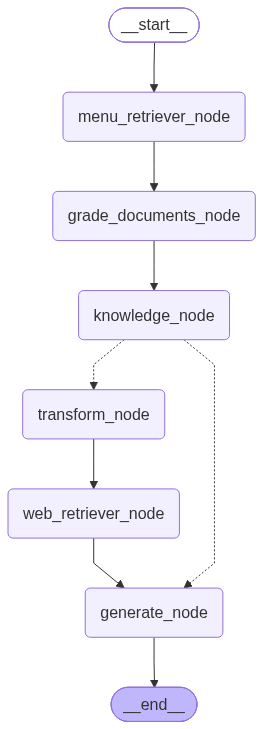

In [233]:
graph_crag = builder_crag.compile()
display(Image(graph_crag.get_graph().draw_mermaid_png()))

그래프를 실행한다.

In [234]:
question = {'question': '스테이크 메뉴의 가격은 얼마인가요?'}
graph_crag.invoke(question)

----- 문서 검색 -----
----- 문서 관련성 평가 -----
----- 문서 관련성 있음 -----
----- 지식 정제 -----
----- 정제된 지식 추가 -----
----- 평가된 문서 분석 -----
----- 답변 생성 => 답변을 생성하는 노드 generate_node로 분기한다. -----
----- 답변 생성 -----


{'messages': [AIMessage(content='스테이크 메뉴의 가격은 ₩35,000입니다.', additional_kwargs={}, response_metadata={}, id='45ae936f-42c0-4d66-bdcb-d1bb1d1a4a04')],
 'question': '스테이크 메뉴의 가격은 얼마인가요?',
 'generation': '스테이크 메뉴의 가격은 ₩35,000입니다.',
 'documents': [(Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'),
   'ambiguous'),
  (Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '8', 'menu_name': '안심 스테이크 샐러드'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 

In [236]:
for output in graph_crag.stream({'question': '스테이크 메뉴의 가격은 얼마인가요?'}):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'상태: {value.keys()}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)
        
print(f'최종 답변:\n{value["generation"]}')

----- 문서 검색 -----
실행한 노드: menu_retriever_node
상태: dict_keys(['documents'])
노드를 실행한 결과: {'documents': [(Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'menu_number': '1', 'menu_name': '시그니처 스테이크', 'source': './data/restaurant_menu.txt'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), 'ambiguous'), (Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'menu_name': '안심 스테이크 샐러드', 'source': './data/restaurant_menu.txt', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.'), 'ambiguous')]}
----------------------------------------------------------------------------------------------------
----- 문

In [237]:
for output in graph_crag.stream({'question': '스테이크에 어울리는 와인을 추천해주세요.'}):
    for key, value in output.items():
        print(f'실행한 노드: {key}')
        print(f'상태: {value.keys()}')
        print(f'노드를 실행한 결과: {value}')
        print('-' * 100)
        
print(f'최종 답변:\n{value["generation"]}')

----- 문서 검색 -----
실행한 노드: menu_retriever_node
상태: dict_keys(['documents'])
노드를 실행한 결과: {'documents': [(Document(id='65f7997f-5023-4df5-9e12-758ff15f3d20', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '1', 'menu_name': '시그니처 스테이크'}, page_content='1. 시그니처 스테이크\n    가격: ₩35,000\n    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스\n    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.'), 'ambiguous'), (Document(id='92ce1649-cf01-477b-b970-9617525966c5', metadata={'source': './data/restaurant_menu.txt', 'menu_name': '안심 스테이크 샐러드', 'menu_number': '8'}, page_content='8. 안심 스테이크 샐러드\n    가격: ₩26,000\n    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈\n    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.'), 'ambiguous')]}
----------------------------------------------------------------------------------------------------
----- 문